In [ ]:
"""
Let's see if I can inspect the df results but better this time
also fourier stuff is in here
"""

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

In [2]:
import plot_time_series as pts
import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [20]:
def reduce_max_3(df, imagenobg, thr=300):
    drop_indices = []
    for index in df.index.to_numpy():
        row = int(df.loc[index]["row_from_nn"]) + 10
        col = int(df.loc[index]["col_from_nn"]) + 10
        littlerstamp = imagenobg[row - 4 : row + 4, col - 4 : col + 4]

        if np.max(littlerstamp) < thr:
            drop_indices.append(index)
    newdf = df.drop(drop_indices)
    return newdf

In [ ]:
# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("alllist")
]  # Adjust this to your file format

# Read and process each DataFrame file
for f in files:
    dpath = os.path.join(folder_path, f + "_reduced")

    # Skip if the reduced file already exists
    if os.path.isfile(dpath):
        continue

    df = pd.read_csv(os.path.join(folder_path, f))

    # Reduce based on type != 'cr'
    df_nocr = df[df["type"] != "cr"]

    # Apply other reductions
    df_reduced_edges = rff.reduce_edges(df_nocr, 15)
    df_reduced_edges_size4 = rff.reduce_size(df_reduced_edges, 4)

    # Add the quadrant as a new column
    quad = f[-8]
    df_reduced_edges_size4["quadrant"] = quad

    # these will stay the same
    fname = df.iloc[0]["filename"] + "fits.fz"

    path = fpath + fname
    hdul = fits.open(path)
    file1_array = hdul[quad].data
    background = rff.get_image_background(file1_array)
    imagenobg = file1_array - background

    # Apply the reduce_max function for further reduction

    newdf = reduce_max_3(df_reduced_edges_size4, imagenobg, thr=300)

    # Save the reduced DataFrame
    break
    # newdf.to_csv(dpath)

In [75]:
f[:47]

'ztf_20221020154120_000640_zi_c14_x_0001.fits.fz'

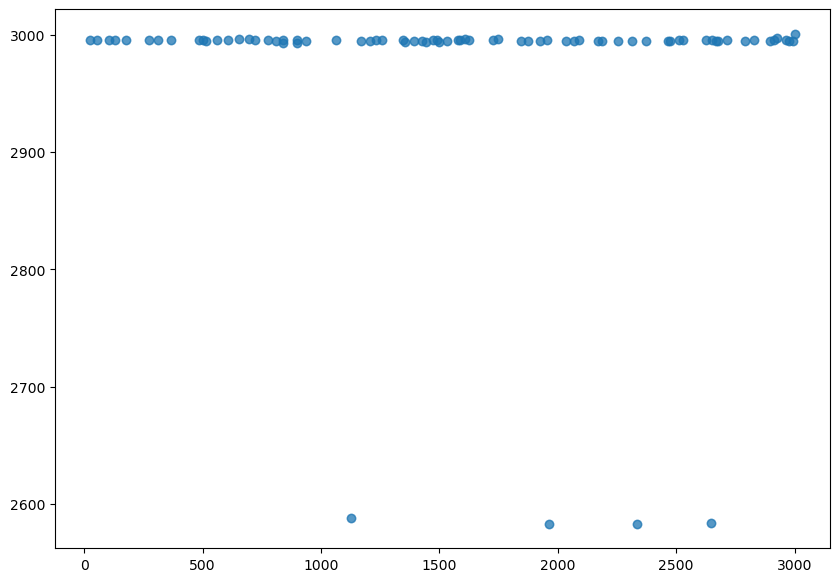

In [61]:
plt.scatter(newdf["row_from_nn"], newdf["col_from_nn"], alpha=0.5)

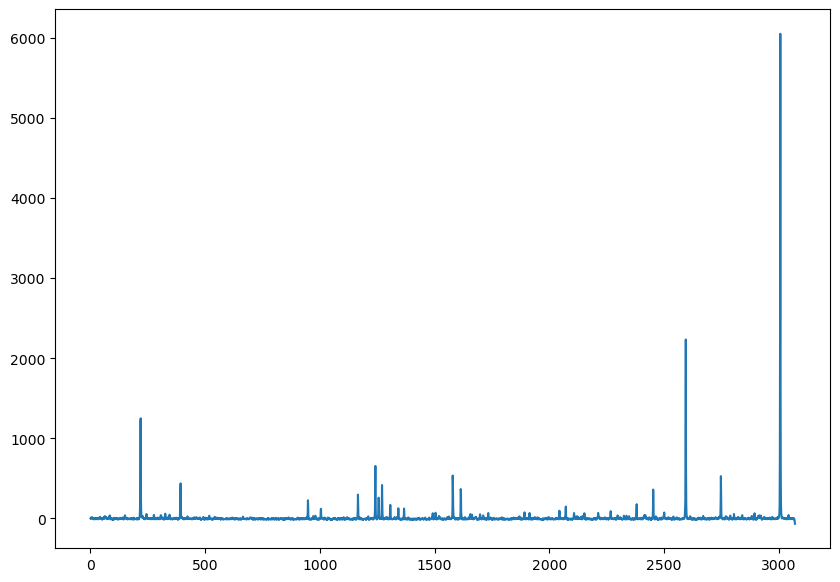

In [69]:
plt.plot(imagenobg[500, :])

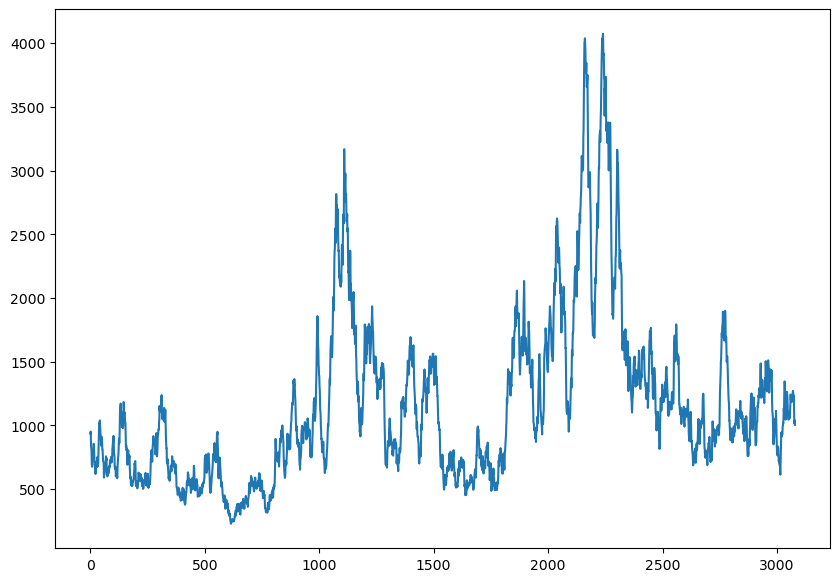

In [71]:
plt.plot(imagenobg[:, 2995 + 10])

In [5]:
def inspect_df_with_quadrant(df, direcname):
    wid = 10
    figcols = 5
    figrows = 1 + len(df) // figcols
    fig, ax = plt.subplots(figrows, figcols, figsize=(figcols * 1.8, figrows * 1.8))
    for i in range(figrows):
        for j in range(figcols):
            index = figcols * i + j
            if index < len(df):
                fname = df.iloc[index]["filename"] + "fits.fz"
                row = int(df.iloc[index]["row_from_nn"])
                col = int(df.iloc[index]["col_from_nn"])
                quad = int(df.iloc[index]["quadrant"])
                fpath = (
                    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
                    + direcname
                    + "_minus_extras/"
                )
                path = fpath + fname
                hdul = fits.open(path)
                file1_array = hdul[quad].data
                norm = (file1_array - np.min(file1_array)) / (
                    np.max(file1_array) - np.min(file1_array)
                )
                # ax[i, j].imshow(norm[col+wid-10:col+wid+10, row-10+wid:row+10+wid])
                ax[i, j].imshow(
                    np.sqrt(
                        norm[
                            row - 10 + wid : row + 10 + wid,
                            col + wid - 10 : col + wid + 10,
                        ]
                    )
                )
                ax[i, j].set_axis_off()
                # ax[i, j].set_title(fname[26:-8])
                ax[i, j].set_title(str(index))
    plt.tight_layout()
    plt.show()

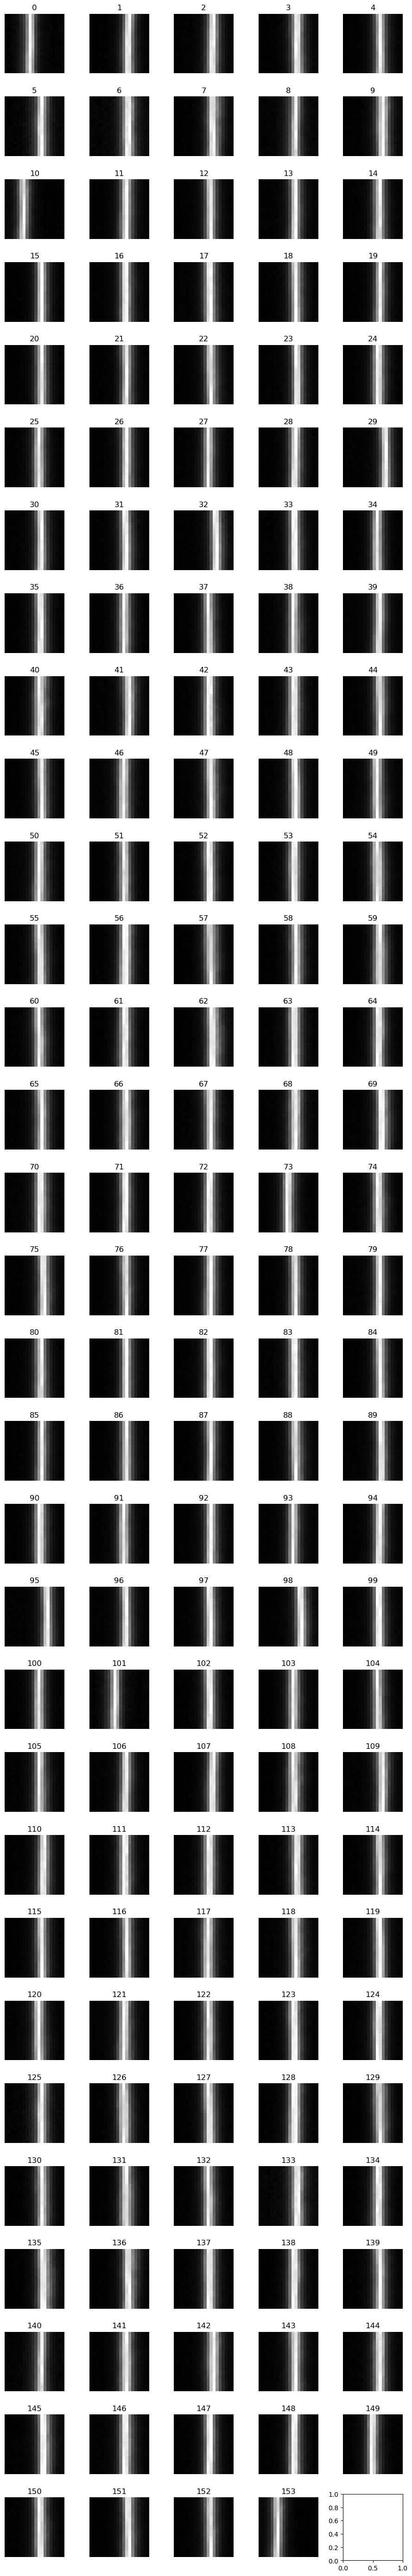

In [59]:
inspect_df_with_quadrant(newdf, "1020")

In [17]:
# we shall return to that later. for now let's figure out
# how many predsarrays we have compared to how many images
# Set the folder path where your DataFrames are stored
# folder_path = '/lustre/lrspec/ZTF_data/science_extractions/1020'

# List all the files in the folder
# files = [f for f in os.listdir(folder_path) if f.endswith('alllist')]
!ls /lustre/lrspec/ZTF_data/science_extractions/1020/*alllist | wc -l
# so we have 4331 alllists

4331


In [21]:
!ls /lustre/lrspec/ZTF_data/science_extractions/1020/*_predsarray_*_predsarray.npy | wc -l

4332


In [18]:
!ls /lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/*.fits.fz | wc -l
# uh but we only have 3749 files?? how does that make sense
# oh cause we have 4x that many
# so right now we have about a quarter done. we're just gonna have to be
# fine with that for now.
# do we have all the dataframes made for all the
# predsarrays that we have? let's check above...
# yes we have all the dataframes for all the predsarrays that we have
# and we have about a quarter of the predsarrays for the image data that we have

3749


In [19]:
4331 / (3749 * 4)

0.28881034942651373

In [6]:
# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("reduced")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df

,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant
0,7,7,ztf_20221020154120_000640_zi_c10_x_0017.,pos,87.000000,889.000000,5.0,4
1,12,12,ztf_20221020154120_000640_zi_c10_x_0017.,pos,156.500000,889.000000,6.0,4
2,15,15,ztf_20221020154120_000640_zi_c10_x_0017.,pos,181.000000,536.000000,5.0,4
3,40,40,ztf_20221020154120_000640_zi_c10_x_0017.,pos,666.500000,536.333333,6.0,4
4,49,49,ztf_20221020154120_000640_zi_c10_x_0017.,pos,809.500000,889.000000,6.0,4
...,...,...,...,...,...,...,...,...
614006,214,214,ztf_20221020157697_000640_zi_c15_x_0028.,both,2814.000000,863.500000,6.0,3
614007,216,216,ztf_20221020157697_000640_zi_c15_x_0028.,both,2886.500000,1271.400000,10.0,3
614008,219,219,ztf_20221020157697_000640_zi_c15_x_0028.,both,2990.600000,1271.200000,5.0,3
614009,220,220,ztf_20221020157697_000640_zi_c15_x_0028.,both,3019.285714,1271.428571,7.0,3


In [9]:
big = concatenated_df[concatenated_df["detection_size"] > 1000]

In [10]:
big

,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant
21700,608,608,ztf_20221020148032_000686_zg_c09_x_0028.,neg,2554.043398,154.498615,1083.0,4
21798,852,852,ztf_20221020148032_000686_zg_c09_x_0028.,both,408.072044,153.578700,1277.0,4
21841,941,941,ztf_20221020148032_000686_zg_c09_x_0028.,both,809.079932,153.898810,1176.0,4
21882,1019,1019,ztf_20221020148032_000686_zg_c09_x_0028.,both,1251.557467,153.872557,1279.0,4
21956,1165,1165,ztf_20221020148032_000686_zg_c09_x_0028.,both,2041.086907,154.437923,1772.0,4
...,...,...,...,...,...,...,...,...
606009,424,424,ztf_20221020141806_000686_zi_c04_x_0006.,both,2650.516489,740.509699,2062.0,3
612957,0,0,ztf_20221020148032_000686_zg_c16_x_0014.,pos,157.145279,1372.726064,3008.0,1
612960,9,9,ztf_20221020148032_000686_zg_c16_x_0014.,pos,1150.333240,1055.880911,14317.0,1
612992,222,222,ztf_20221020148032_000686_zg_c16_x_0014.,both,166.611193,1372.729884,4735.0,1


In [8]:
plot_time_series_again_aperture(concatenated_df, 48469, "1020")

NameError: name 'plot_time_series_again_aperture' is not defined

In [11]:
inspect_df_with_quadrant(big, "1020")

KeyboardInterrupt: 

Error in callback <function flush_figures at 0x2b638cd03100> (for post_execute):


KeyboardInterrupt: 

In [87]:
medium = concatenated_df[concatenated_df["detection_size"] > 10]
medium = medium[medium["detection_size"] < 70]
mediumpos = medium[medium["type"] == "pos"]
mediumneg = medium[medium["type"] == "neg"]
len(mediumneg)

10478

In [154]:
smol = concatenated_df[concatenated_df["detection_size"] < 10]
len(smol)

33814

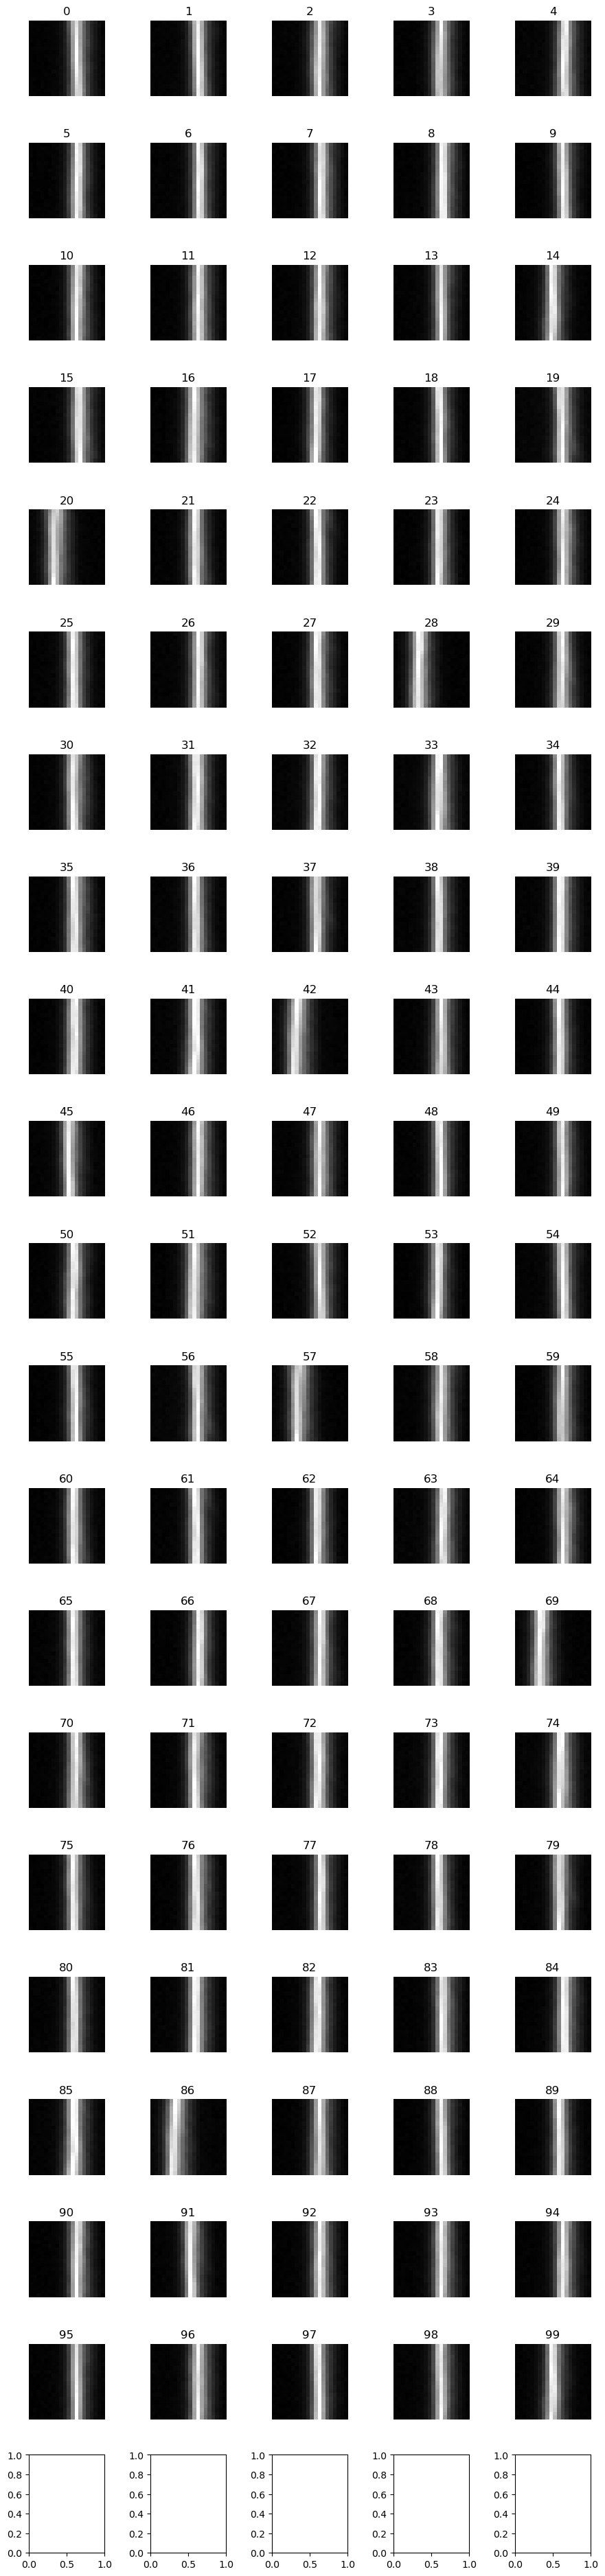

In [155]:
inspect_df_with_quadrant(smol[:100], "1020")

In [95]:
# are there any that only have like a couple transients?

# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("reduced")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    if len(df) < 10:
        dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_solos = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_solos

,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant
0,3,3,ztf_20221020157697_000640_zi_c02_x_0028.,pos,1638.500000,122.000000,6.0,1
1,17,17,ztf_20221020157697_000640_zi_c02_x_0028.,neg,1647.200000,122.600000,5.0,1
2,44,44,ztf_20221020157697_000640_zi_c02_x_0028.,both,1638.500000,122.000000,6.0,1
3,45,45,ztf_20221020157697_000640_zi_c02_x_0028.,both,1647.200000,122.600000,5.0,1
4,9,9,ztf_20221020157697_000640_zi_c14_x_0015.,neg,783.200000,2972.300000,10.0,3
...,...,...,...,...,...,...,...,...
1742,3,3,ztf_20221020157697_000640_zi_c06_x_0019.,pos,1950.200000,556.900000,10.0,3
1743,21,21,ztf_20221020157697_000640_zi_c06_x_0019.,both,486.842105,556.368421,19.0,3
1744,29,29,ztf_20221020157697_000640_zi_c06_x_0019.,both,1950.200000,556.900000,10.0,3
1745,1,1,ztf_20221020297847_000449_zr_c09_x_0024.,pos,2276.760000,73.860000,50.0,2


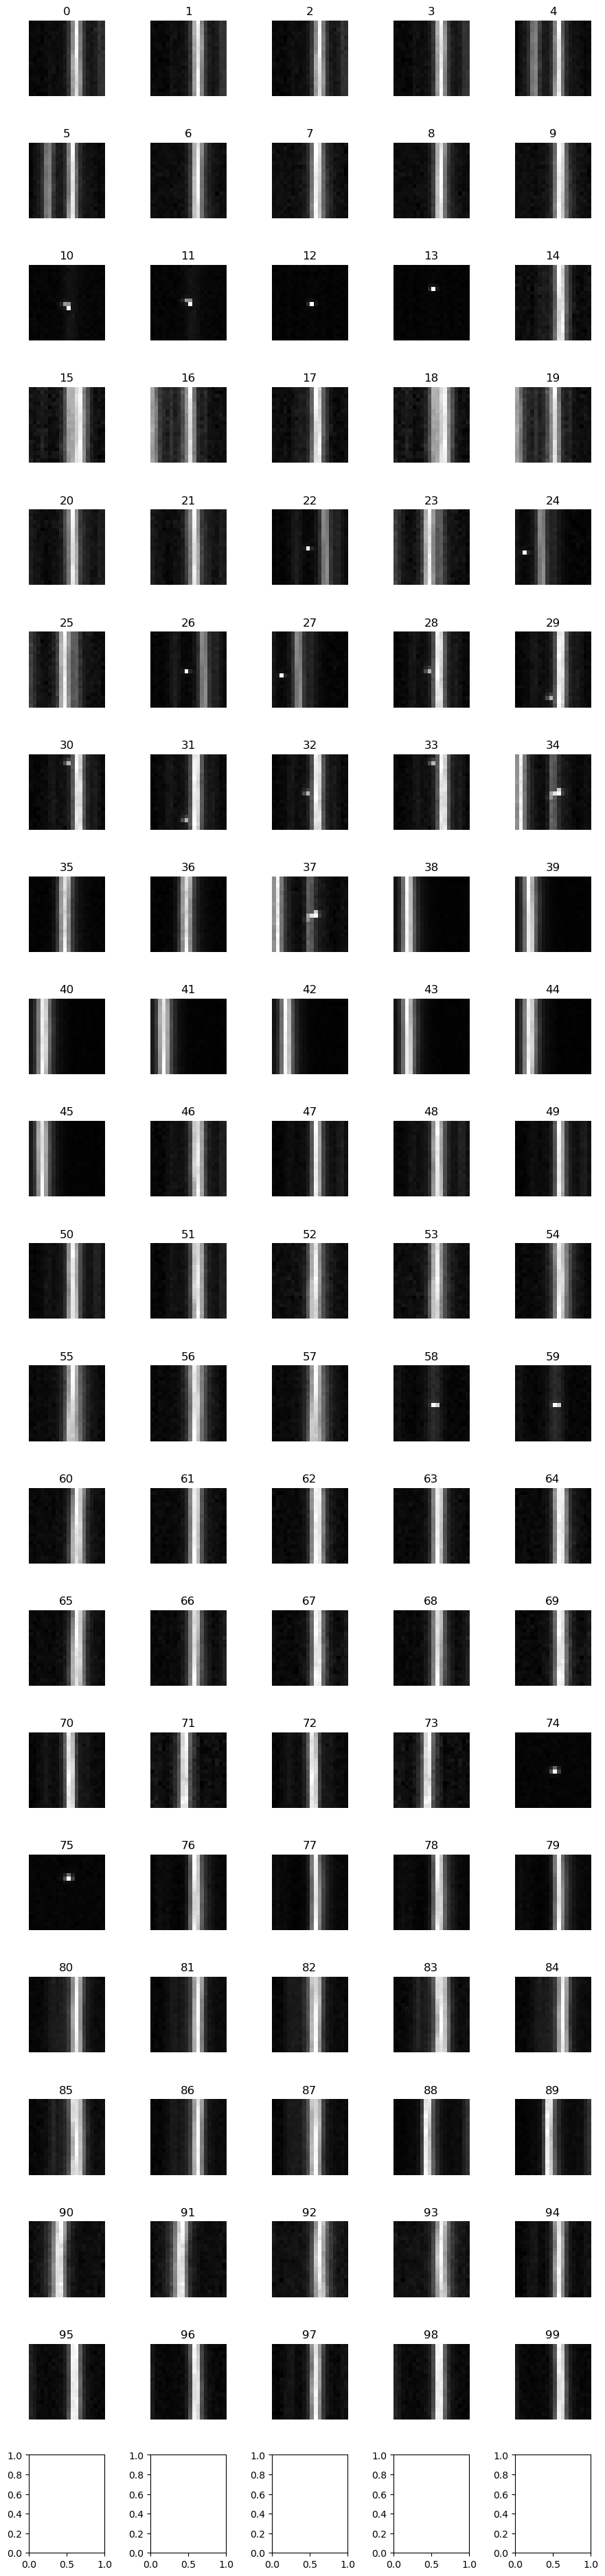

In [97]:
inspect_df_with_quadrant(concatenated_df_solos[:100], "1020")

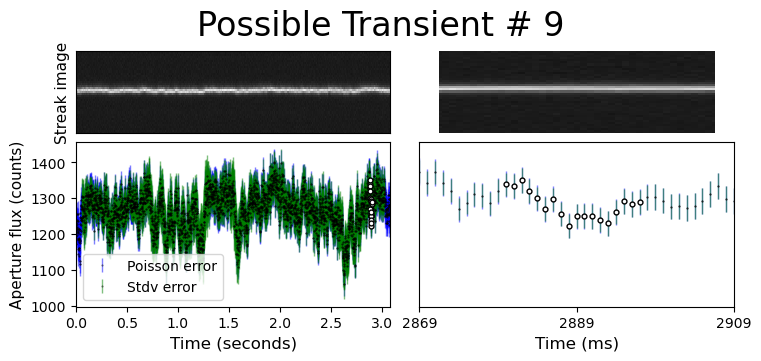

In [148]:
plot_time_series_again_aperture(concatenated_df_solos, 9, "1020")

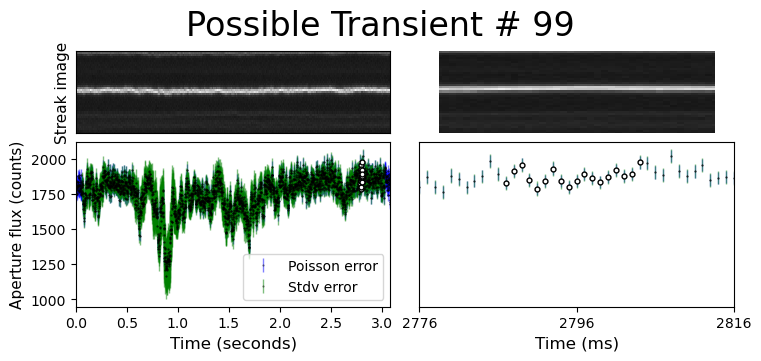

In [157]:
plot_time_series_again_aperture(concatenated_df_solos, 99, "1020")

In [12]:
def plot_time_series_again_aperture(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10
    quad = int(df.loc[index]["quadrant"])

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(
        imagenobackground[row - 10 : row + 10, col - 7 : col + 7], axis=0
    )
    zeropoint = col - 7

    maxind = np.argmax(averages)
    if averages[maxind - 1] > averages[maxind + 1]:
        column_indices = [
            zeropoint + maxind - 2,
            zeropoint + maxind - 1,
            zeropoint + maxind,
            zeropoint + maxind + 1,
        ]
    else:
        column_indices = [
            zeropoint + maxind + 2,
            zeropoint + maxind - 1,
            zeropoint + maxind,
            zeropoint + maxind + 1,
        ]

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Aperture flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=0.3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 20, row + 20)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 20, row + 20)
    axd["lower mid"].set_xticks(np.linspace(row - 20, row + 20, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Possible Transient # " + str(index), fontsize=24)

    plt.show()
    plt.close()

In [150]:
concatenated_df_solos[concatenated_df_solos["type"] == "pos"]

,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant
0,3,3,ztf_20221020157697_000640_zi_c02_x_0028.,pos,1638.500000,122.000000,6.0,1
6,1,1,ztf_20221020297847_000449_zr_c01_x_0022.,pos,1976.500000,1099.500000,8.0,2
10,0,0,ztf_20221020163819_000640_zg_c03_x_0012.,pos,164.600000,925.525000,40.0,3
12,0,0,ztf_20221020297847_000449_zr_c14_x_0000.,pos,1538.000000,2450.500000,36.0,1
22,2,2,ztf_20221020154120_000640_zi_c10_x_0029.,pos,2805.125000,2069.875000,16.0,2
...,...,...,...,...,...,...,...,...
1736,3,3,ztf_20221020297847_000449_zr_c04_x_0011.,pos,1905.891892,2071.432432,37.0,4
1737,4,4,ztf_20221020297847_000449_zr_c04_x_0011.,pos,2577.545455,1622.090909,11.0,4
1741,0,0,ztf_20221020157697_000640_zi_c06_x_0019.,pos,486.842105,556.368421,19.0,3
1742,3,3,ztf_20221020157697_000640_zi_c06_x_0019.,pos,1950.200000,556.900000,10.0,3


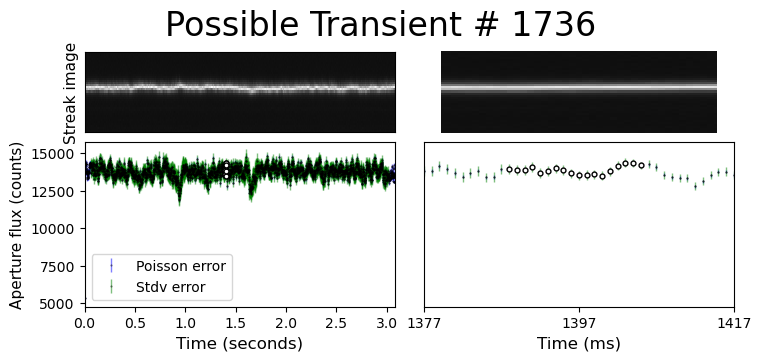

In [13]:
plot_time_series_again_aperture(concatenated_df, 1736, "1020")

/tmp/ipykernel_23723/1210281064.py:75: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


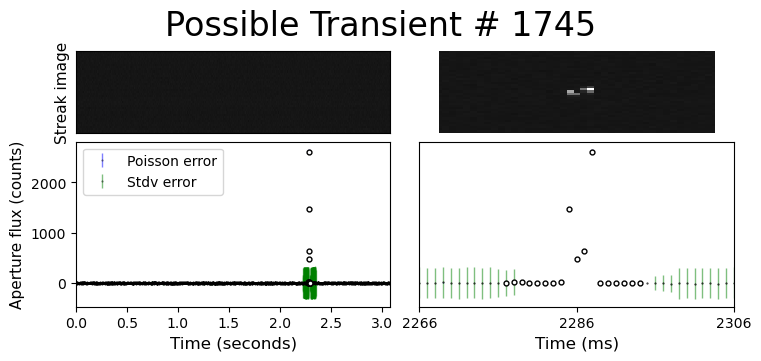

In [151]:
plot_time_series_again_aperture(concatenated_df_solos, 1745, "1020")

In [4]:
# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("sobelratio")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_sobel = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_sobel

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
0,0,34,34,ztf_20221020154120_000640_zi_c09_x_0017.,pos,173.500000,592.000000,6.0,4,22.759903
1,1,56,56,ztf_20221020154120_000640_zi_c09_x_0017.,pos,307.000000,592.000000,5.0,4,19.525473
2,2,71,71,ztf_20221020154120_000640_zi_c09_x_0017.,pos,399.076923,592.230769,13.0,4,12.377268
3,3,77,77,ztf_20221020154120_000640_zi_c09_x_0017.,pos,426.833333,592.166667,6.0,4,20.345509
4,4,85,85,ztf_20221020154120_000640_zi_c09_x_0017.,pos,463.000000,1751.833333,18.0,4,16.250433
...,...,...,...,...,...,...,...,...,...,...
614006,173,508,508,ztf_20221020138241_000686_zi_c15_x_0029.,both,2887.000000,523.000000,5.0,1,19.482388
614007,174,510,510,ztf_20221020138241_000686_zi_c15_x_0029.,both,2903.500000,523.250000,8.0,1,20.777689
614008,175,514,514,ztf_20221020138241_000686_zi_c15_x_0029.,both,2951.666667,523.333333,27.0,1,12.660818
614009,176,517,517,ztf_20221020138241_000686_zi_c15_x_0029.,both,2972.625000,523.375000,8.0,1,26.944208


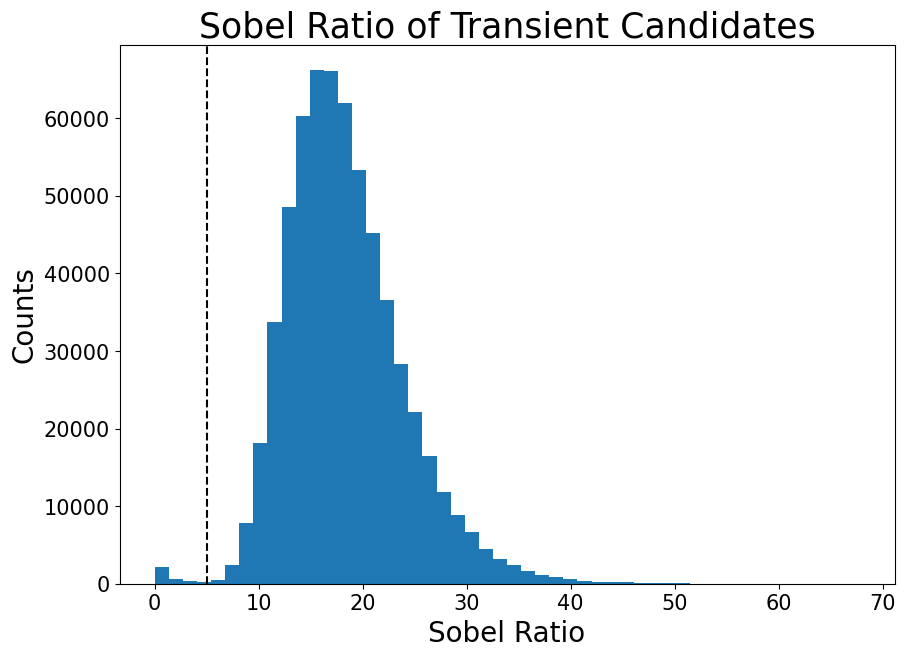

In [6]:
plt.hist(concatenated_df_sobel["sobel_ratio"], bins=50)
# plt.yscale('log')
plt.title("Sobel Ratio of Transient Candidates", fontsize=25)
plt.ylabel("Counts", fontsize=20)
plt.xlabel("Sobel Ratio", fontsize=20)
# plt.xlim(0,20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.axvline(5, c="black", ls="dashed")
# plt.scatter(-13, 1)

(array([  66.,    8.,    0.,    4.,    0.,    6.,   14.,   52.,  204.,
         329.,  554.,  807., 1018., 1047., 1279., 1348., 1323., 1286.,
        1115., 1060.,  953.,  830.,  611.,  546.,  428.,  349.,  256.,
         200.,  158.,  116.,  108.,   86.,   60.,   36.,   28.,   32.,
          14.,   24.,   18.,    4.,   16.,    4.,    2.,    4.,    0.,
           6.,    2.,    2.,    0.,    2.]),
 array([ 0.60591304,  1.57061493,  2.53531681,  3.50001869,  4.46472058,
         5.42942246,  6.39412435,  7.35882623,  8.32352811,  9.28823   ,
        10.25293188, 11.21763376, 12.18233565, 13.14703753, 14.11173942,
        15.0764413 , 16.04114318, 17.00584507, 17.97054695, 18.93524884,
        19.89995072, 20.8646526 , 21.82935449, 22.79405637, 23.75875825,
        24.72346014, 25.68816202, 26.65286391, 27.61756579, 28.58226767,
        29.54696956, 30.51167144, 31.47637332, 32.44107521, 33.40577709,
        34.37047898, 35.33518086, 36.29988274, 37.26458463, 38.22928651,
        39.19398

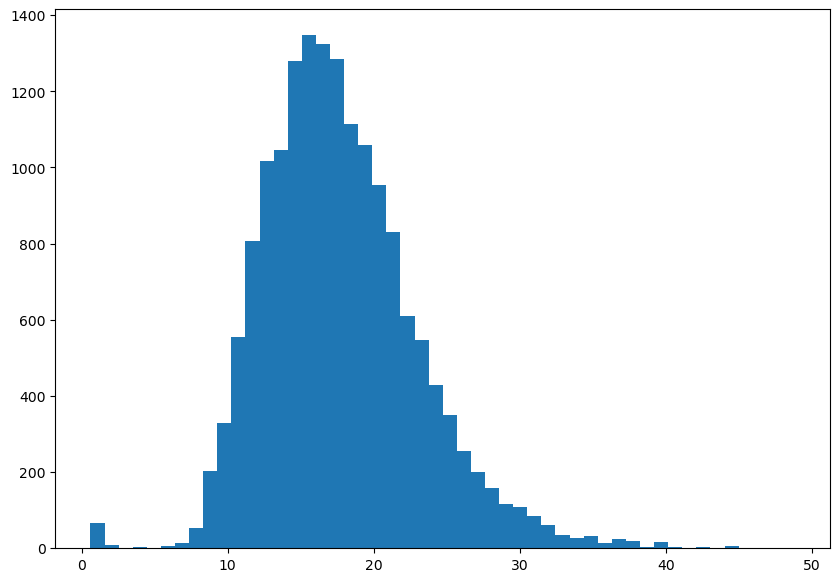

In [185]:
plt.hist(concatenated_df_sobel["sobel_ratio"], bins=50)

In [5]:
maybecrs = concatenated_df_sobel[concatenated_df_sobel["sobel_ratio"] < 5]
len(maybecrs)

3108

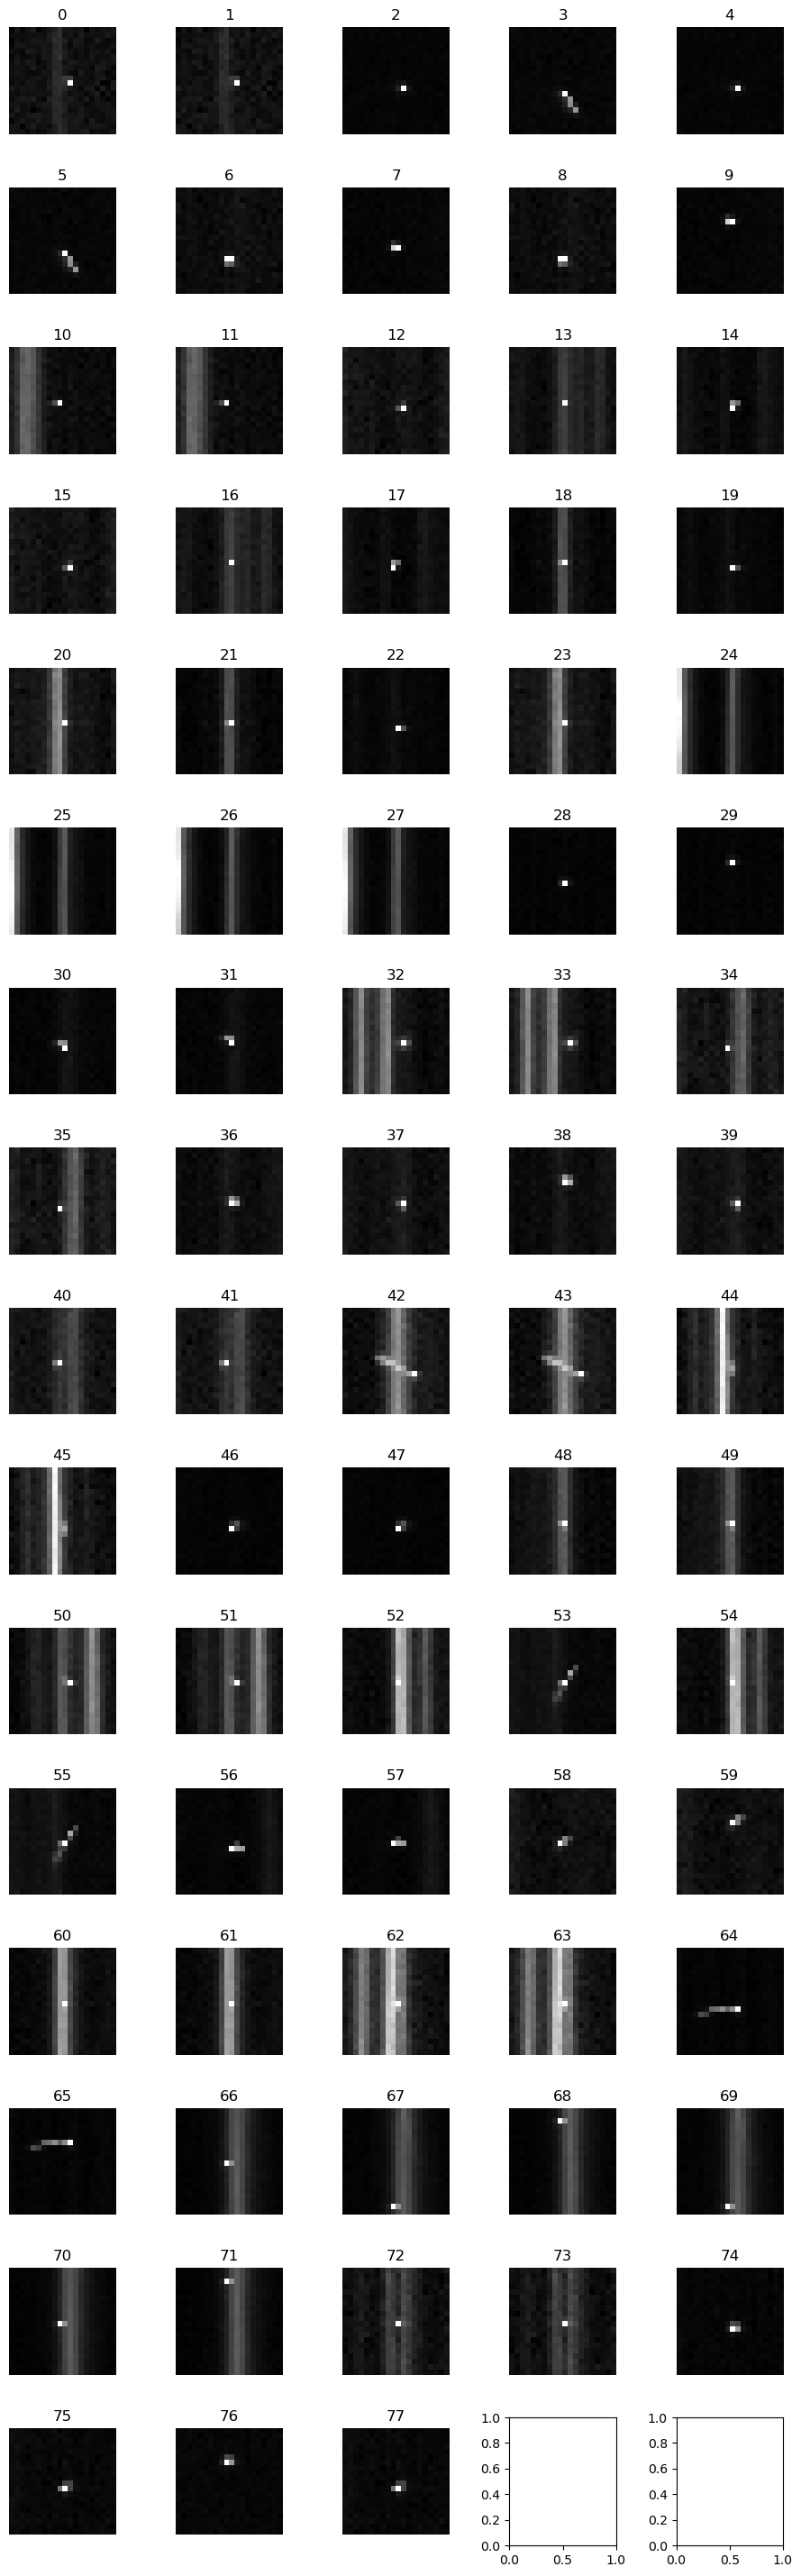

In [188]:
inspect_df_with_quadrant(maybecrs, "1020")

In [16]:
nocrs = concatenated_df_sobel[concatenated_df_sobel["sobel_ratio"] > 5]

In [18]:
len(concatenated_df_sobel) - len(nocrs)

3108

In [17]:
len(nocrs)

610903

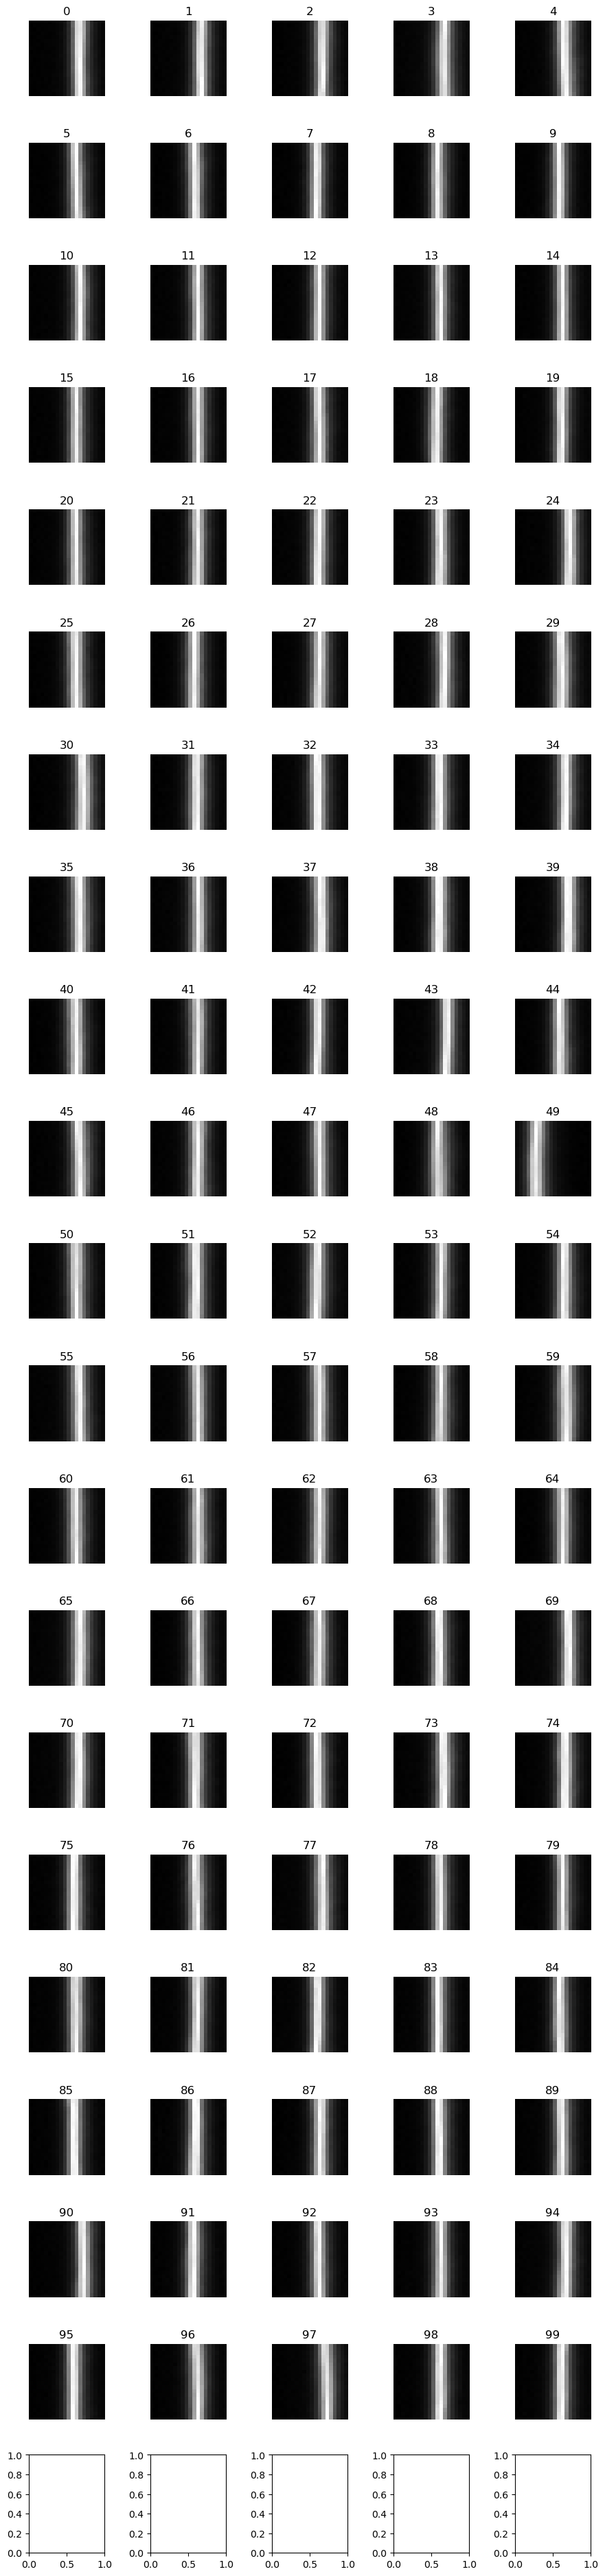

In [190]:
inspect_df_with_quadrant(nocrs[:100], "1020")

In [191]:
whatsthat = concatenated_df_sobel[concatenated_df_sobel["sobel_ratio"] > 35]

In [194]:
whatsthat

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
9,9,271,271,ztf_20221020297847_000449_zr_c12_x_0013.,neg,173.000000,1030.000000,5.0,2,36.658642
20,20,291,291,ztf_20221020297847_000449_zr_c12_x_0013.,neg,508.500000,1029.500000,6.0,2,39.748932
36,36,320,320,ztf_20221020297847_000449_zr_c12_x_0013.,neg,1006.333333,1028.666667,9.0,2,44.808281
69,69,363,363,ztf_20221020297847_000449_zr_c12_x_0013.,neg,2016.000000,1027.000000,7.0,2,35.253647
93,93,400,400,ztf_20221020297847_000449_zr_c12_x_0013.,neg,2569.230769,1029.461538,13.0,2,37.311436
...,...,...,...,...,...,...,...,...,...,...
15690,171,1209,1209,ztf_20221020141806_000686_zi_c04_x_0007.,both,3020.000000,1997.000000,5.0,1,36.565250
16130,65,158,158,ztf_20221020148032_000686_zg_c06_x_0005.,neg,1548.166667,1521.166667,6.0,4,35.803814
16231,166,350,350,ztf_20221020148032_000686_zg_c06_x_0005.,both,1548.166667,1521.166667,6.0,4,35.803814
16330,27,111,111,ztf_20221020157697_000640_zi_c08_x_0023.,neg,1707.500000,2448.000000,6.0,2,35.205997


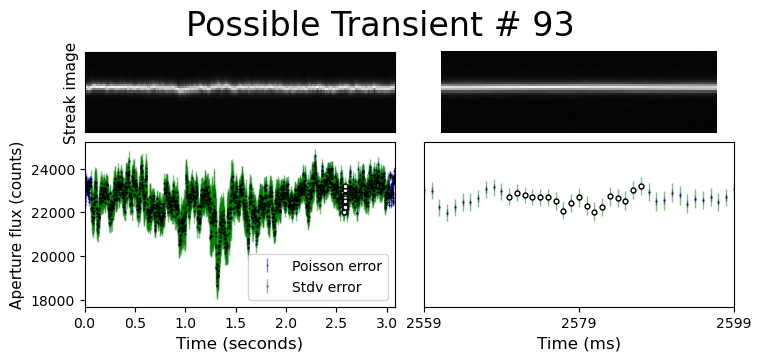

In [196]:
plot_time_series_again_aperture(concatenated_df_sobel, 93, "1020")

In [198]:
len(nocrs)

16337

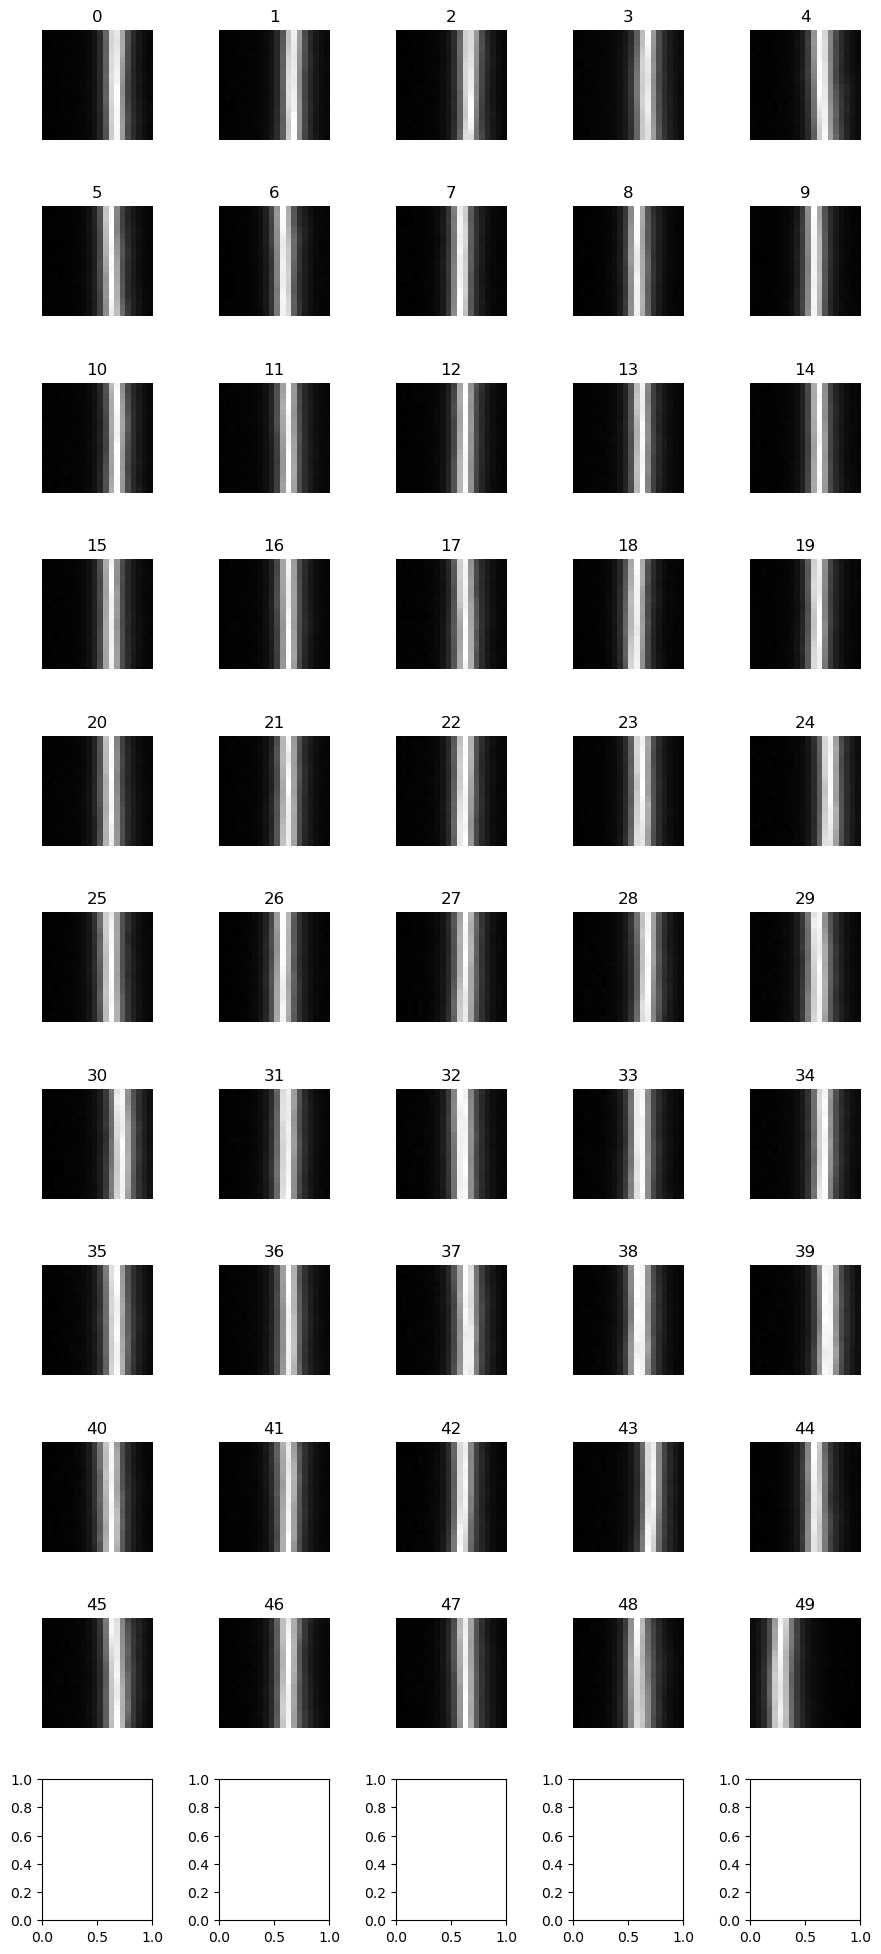

In [197]:
inspect_df_with_quadrant(nocrs[:50], "1020")

In [200]:
# okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
direcname = "1020"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)


# List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("sobelratio")
]  # Adjust this to your file format


# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    if len(df) < 4:
        dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_sobel_small = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_sobel_small

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
0,0,10,10,ztf_20221020141806_000686_zi_c06_x_0016.,neg,2689.500000,692.500000,6.0,3,16.237982
1,1,21,21,ztf_20221020141806_000686_zi_c06_x_0016.,both,2689.500000,692.500000,6.0,3,16.237982
2,0,1,1,ztf_20221020297847_000449_zr_c05_x_0013.,pos,1732.000000,1704.000000,27.0,4,0.843457
3,1,2,2,ztf_20221020297847_000449_zr_c05_x_0013.,pos,1986.857143,559.714286,7.0,4,12.696575
4,2,28,28,ztf_20221020297847_000449_zr_c05_x_0013.,both,1986.857143,559.714286,7.0,4,12.696575
...,...,...,...,...,...,...,...,...,...,...
180,1,5,5,ztf_20221020138241_000686_zi_c08_x_0010.,both,2473.200000,687.400000,5.0,2,17.733942
181,0,4,4,ztf_20221020154120_000640_zi_c01_x_0008.,neg,1077.000000,2048.166667,6.0,4,12.375568
182,1,22,22,ztf_20221020154120_000640_zi_c01_x_0008.,both,1077.000000,2048.166667,6.0,4,12.375568
183,0,15,15,ztf_20221020294271_000449_zr_c08_x_0024.,pos,1647.718750,21.687500,32.0,4,0.998492


In [201]:
nocrs_small = concatenated_df_sobel_small[
    concatenated_df_sobel_small["sobel_ratio"] > 5
]

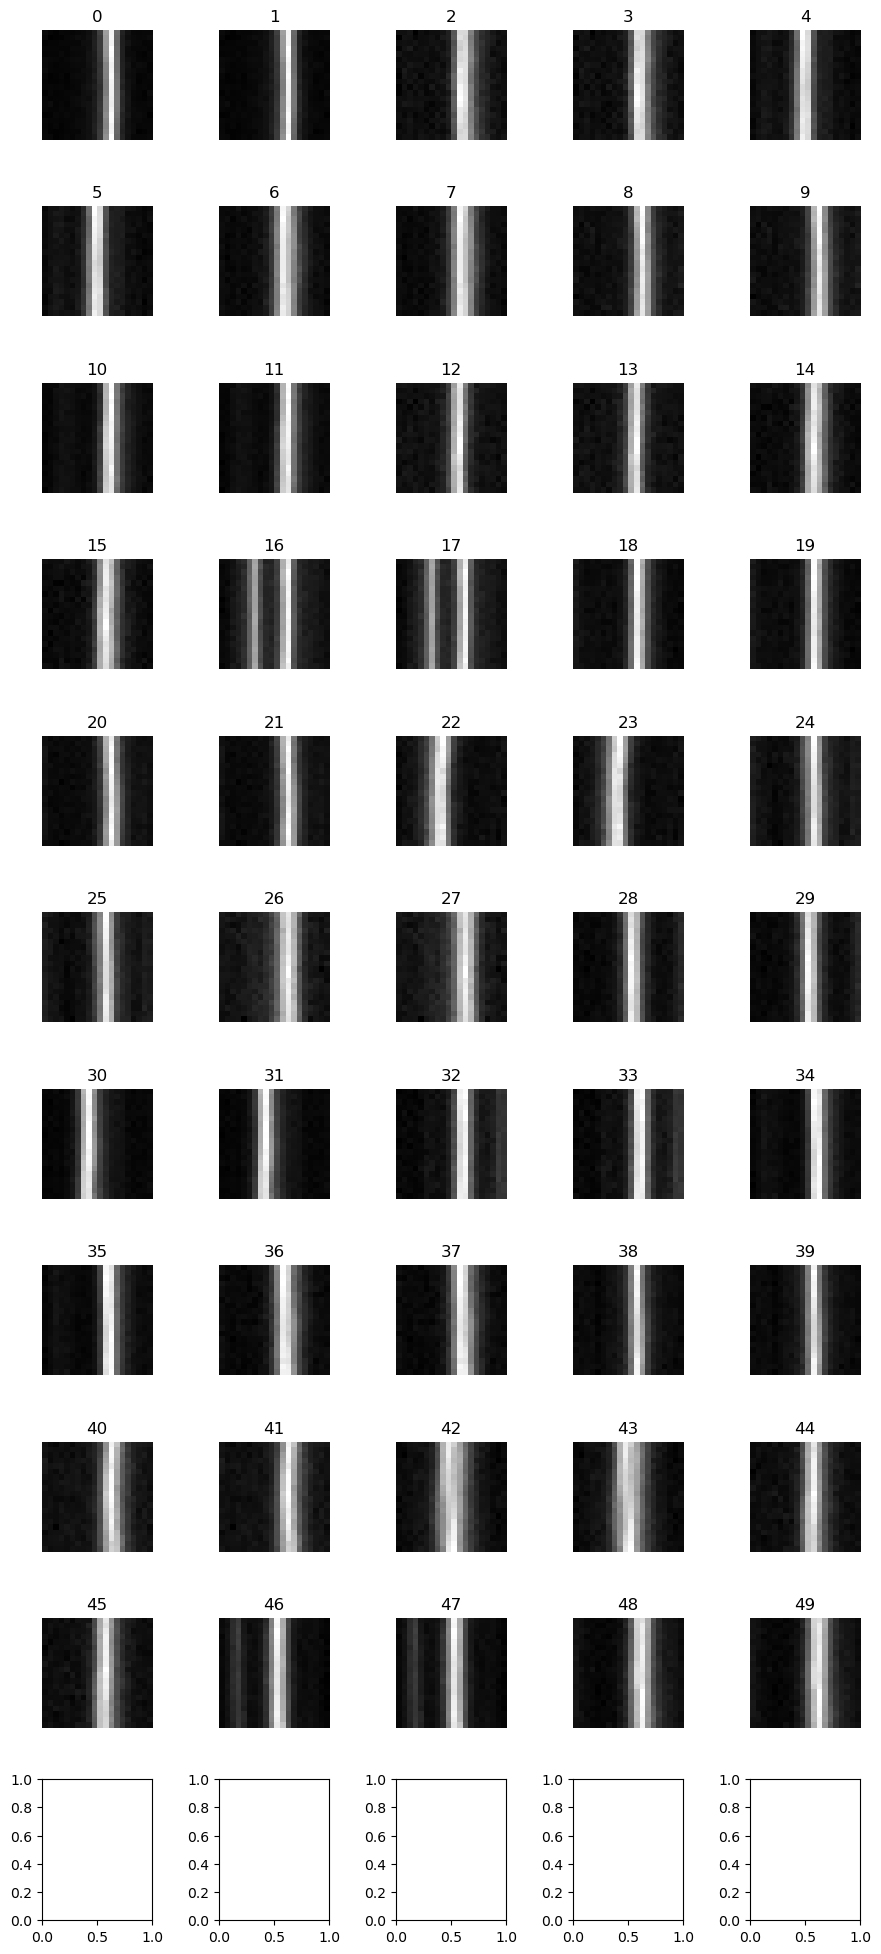

In [203]:
# len(nocrs_small)
inspect_df_with_quadrant(nocrs_small[:50], "1020")

In [ ]:
nocrs_small

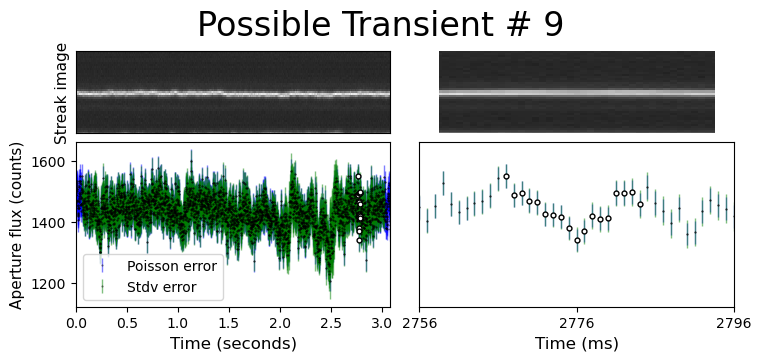

In [205]:
plot_time_series_again_aperture(concatenated_df_sobel_small, 9, "1020")

In [36]:
concatenated_df[:11]

,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant
0,7,7,ztf_20221020154120_000640_zi_c10_x_0017.,pos,87.000000,889.000000,5.0,4
1,12,12,ztf_20221020154120_000640_zi_c10_x_0017.,pos,156.500000,889.000000,6.0,4
2,15,15,ztf_20221020154120_000640_zi_c10_x_0017.,pos,181.000000,536.000000,5.0,4
3,40,40,ztf_20221020154120_000640_zi_c10_x_0017.,pos,666.500000,536.333333,6.0,4
4,49,49,ztf_20221020154120_000640_zi_c10_x_0017.,pos,809.500000,889.000000,6.0,4
5,50,50,ztf_20221020154120_000640_zi_c10_x_0017.,pos,811.941176,536.823529,17.0,4
6,59,59,ztf_20221020154120_000640_zi_c10_x_0017.,pos,878.000000,889.500000,6.0,4
7,78,78,ztf_20221020154120_000640_zi_c10_x_0017.,pos,1089.777778,889.444444,9.0,4
8,93,93,ztf_20221020154120_000640_zi_c10_x_0017.,pos,1244.222222,536.555556,9.0,4
9,100,100,ztf_20221020154120_000640_zi_c10_x_0017.,pos,1332.666667,889.333333,9.0,4


In [41]:
def plot_time_series_again_aperture_tracking(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10
    quad = int(df.loc[index]["quadrant"])

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 7
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, col - 7 : col + 7]) + zeropoint
        maxcols[r] = maxcol
        combined = (
            imagenobackground[r, maxcol - 2]
            + imagenobackground[r, maxcol - 1]
            + imagenobackground[r, maxcol]
            + imagenobackground[r, maxcol + 1]
            + imagenobackground[r, maxcol + 2]
        )
        # print(combined)
        tot[r] = round(combined)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols - 1)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols - 2)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols + 1)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols + 2)
    #     averages = np.average(imagenobackground[row-10:row+10, col-7:col+7], axis=0)
    #     zeropoint = col-7

    #     maxind = np.argmax(averages)
    #     if averages[maxind-1]>averages[maxind+1]:
    #         column_indices = [zeropoint + maxind-2,zeropoint + maxind-1,zeropoint + maxind,zeropoint + maxind+1]
    #     else:
    #         column_indices = [zeropoint + maxind+2,zeropoint + maxind-1,zeropoint + maxind,zeropoint + maxind+1]

    #     streaks = np.zeros(( len(column_indices), len(image[:,column])))
    #     for i, inde in enumerate(column_indices):
    #         streaks[i] = imagenobackground[:,inde]
    #          # streaks[i] = image[:,inde]
    #     streakavg = np.average(streaks, axis=0)
    #     tot = np.sum(streaks, axis=0)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt
    streakavg = tot  # i don't use this any more

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Aperture flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=0.3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 20, row + 20)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 20, row + 20)
    axd["lower mid"].set_xticks(np.linspace(row - 20, row + 20, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Possible Transient # " + str(index), fontsize=24)

    plt.show()
    plt.close()

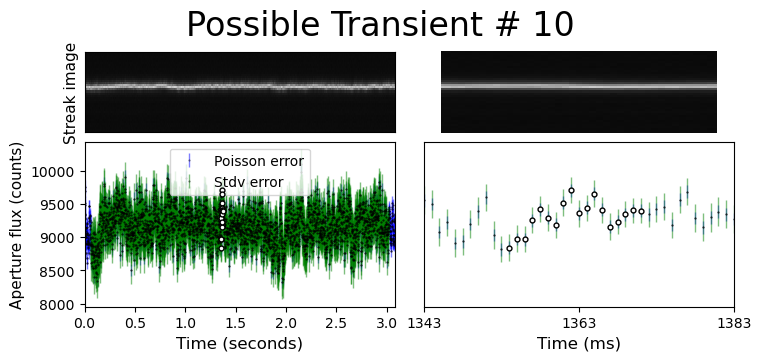

In [31]:
plot_time_series_again_aperture(concatenated_df, 10, "1020")

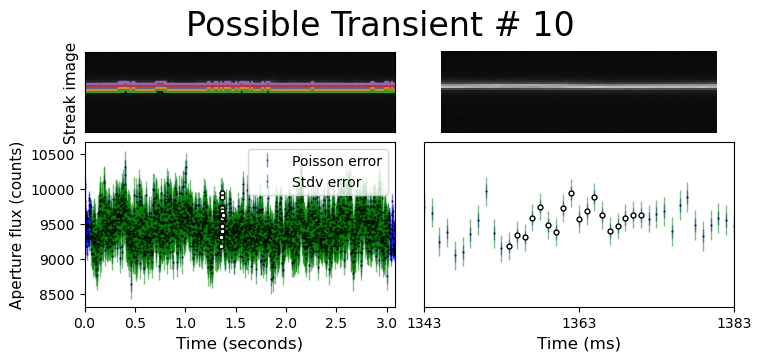

In [42]:
plot_time_series_again_aperture_tracking(concatenated_df, 10, "1020")

In [69]:
def plot_tracking(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10
    quad = int(df.loc[index]["quadrant"])

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(height_ratios=[2, 2])

    fig, axd = plt.subplot_mosaic(
        [["upper left"], ["lower left"]],
        gridspec_kw=gs_kw,
        figsize=(10, 7),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 7
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, col - 7 : col + 7]) + zeropoint
        maxcols[r] = maxcol
        combined = (
            imagenobackground[r, maxcol - 2]
            + imagenobackground[r, maxcol - 1]
            + imagenobackground[r, maxcol]
            + imagenobackground[r, maxcol + 1]
            + imagenobackground[r, maxcol + 2]
        )
        # print(combined)
        tot[r] = round(combined)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt
    streakavg = tot  # i don't use this any more

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols-1)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols - 2)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols+1)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols + 2)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 10, column + 10)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Aperture flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    plt.show()
    plt.close()

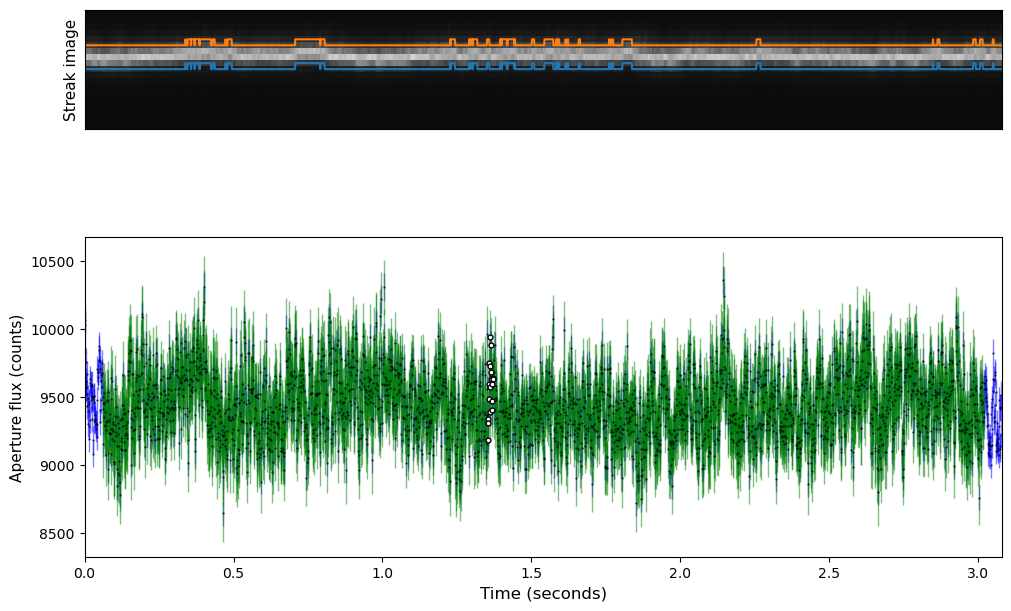

In [73]:
plot_tracking(concatenated_df, 10, "1020")

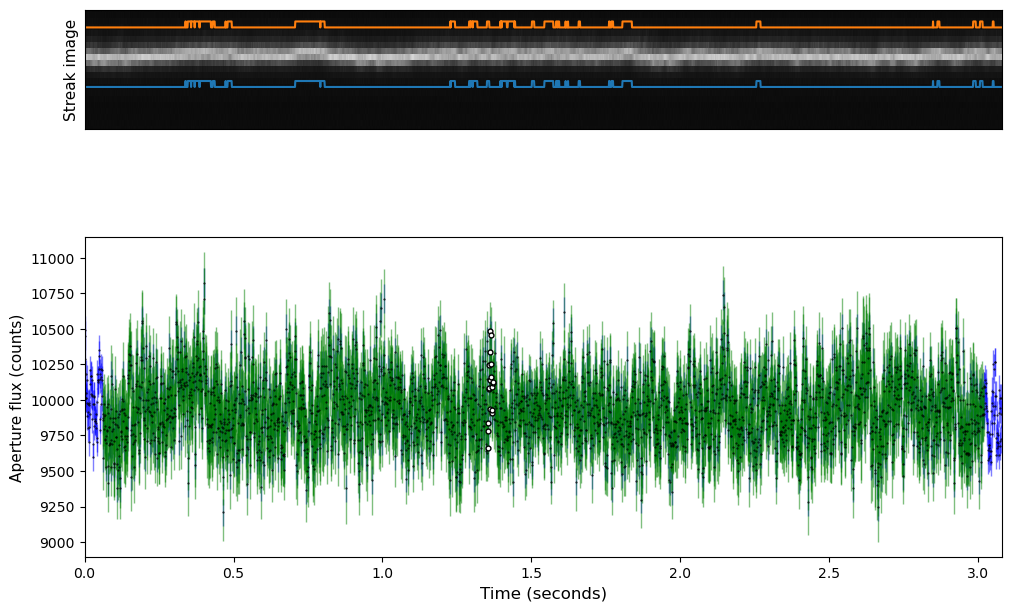

In [72]:
plot_tracking_wide(concatenated_df, 10, "1020")

In [13]:
def plot_tracking_wide(df, index, direcname, quad=False, wideval=5):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # wideval = 5
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10
    if quad == True:
        quad = 1
    else:
        quad = int(df.loc[index]["quadrant"])

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(height_ratios=[2, 2])

    fig, axd = plt.subplot_mosaic(
        [["upper left"], ["lower left"]],
        gridspec_kw=gs_kw,
        figsize=(10, 7),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 20
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 40]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, wideval + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = round(combined)
    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt
    streakavg = tot  # i don't use this any more

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols-1)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols - wideval)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols+1)
    axd["upper left"].plot(range(0, imagenobackground.shape[0]), maxcols + wideval)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Aperture flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    plt.show()
    plt.close()

In [74]:
concatenated_df

,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant
0,7,7,ztf_20221020154120_000640_zi_c10_x_0017.,pos,87.000000,889.000000,5.0,4
1,12,12,ztf_20221020154120_000640_zi_c10_x_0017.,pos,156.500000,889.000000,6.0,4
2,15,15,ztf_20221020154120_000640_zi_c10_x_0017.,pos,181.000000,536.000000,5.0,4
3,40,40,ztf_20221020154120_000640_zi_c10_x_0017.,pos,666.500000,536.333333,6.0,4
4,49,49,ztf_20221020154120_000640_zi_c10_x_0017.,pos,809.500000,889.000000,6.0,4
...,...,...,...,...,...,...,...,...
614006,214,214,ztf_20221020157697_000640_zi_c15_x_0028.,both,2814.000000,863.500000,6.0,3
614007,216,216,ztf_20221020157697_000640_zi_c15_x_0028.,both,2886.500000,1271.400000,10.0,3
614008,219,219,ztf_20221020157697_000640_zi_c15_x_0028.,both,2990.600000,1271.200000,5.0,3
614009,220,220,ztf_20221020157697_000640_zi_c15_x_0028.,both,3019.285714,1271.428571,7.0,3


In [77]:
index = 10
fname = df.iloc[index]["filename"] + "fits.fz"
row = int(df.iloc[index]["row_from_nn"])
col = int(df.iloc[index]["col_from_nn"])
quad = int(df.iloc[index]["quadrant"])
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)
path = fpath + fname
hdul = fits.open(path)
file1_array = hdul[1].data
header = fits.getheader(path)

In [82]:
nocrs

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
0,0,34,34,ztf_20221020154120_000640_zi_c09_x_0017.,pos,173.500000,592.000000,6.0,4,22.759903
1,1,56,56,ztf_20221020154120_000640_zi_c09_x_0017.,pos,307.000000,592.000000,5.0,4,19.525473
2,2,71,71,ztf_20221020154120_000640_zi_c09_x_0017.,pos,399.076923,592.230769,13.0,4,12.377268
3,3,77,77,ztf_20221020154120_000640_zi_c09_x_0017.,pos,426.833333,592.166667,6.0,4,20.345509
4,4,85,85,ztf_20221020154120_000640_zi_c09_x_0017.,pos,463.000000,1751.833333,18.0,4,16.250433
...,...,...,...,...,...,...,...,...,...,...
614006,173,508,508,ztf_20221020138241_000686_zi_c15_x_0029.,both,2887.000000,523.000000,5.0,1,19.482388
614007,174,510,510,ztf_20221020138241_000686_zi_c15_x_0029.,both,2903.500000,523.250000,8.0,1,20.777689
614008,175,514,514,ztf_20221020138241_000686_zi_c15_x_0029.,both,2951.666667,523.333333,27.0,1,12.660818
614009,176,517,517,ztf_20221020138241_000686_zi_c15_x_0029.,both,2972.625000,523.375000,8.0,1,26.944208


In [106]:
def get_rfft_sq(
    index, direcname, df, half_aperture, tracking, plot=False, name="nocrs"
):
    wideval = 2
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10
    quad = int(df.iloc[index]["quadrant"])
    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    image = hdul[quad].data
    column = col
    # image = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    tot, maxcols = get_tot(df, index, direcname, half_aperture, tracking)

    sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
    Fs = 1  # change this if i want to change the sampling rate - right now, it's pixels
    N = len(tot)
    freqs = np.fft.rfftfreq(N, d=1 / Fs)

    pixel_to_ms_factor = 1 / 0.6
    freqs_ms = freqs / pixel_to_ms_factor

    if plot == True:
        plt.plot(freqs_ms[1:], sqfft)
        plt.ylabel("Power")
        plt.xlabel("Frequency (KHz)")  # cycles per millisecond
        plt.title("RFFT^2 of streak " + str(index) + " from df " + str(name))
        # plt.yscale("log")
    return sqfft, freqs_ms

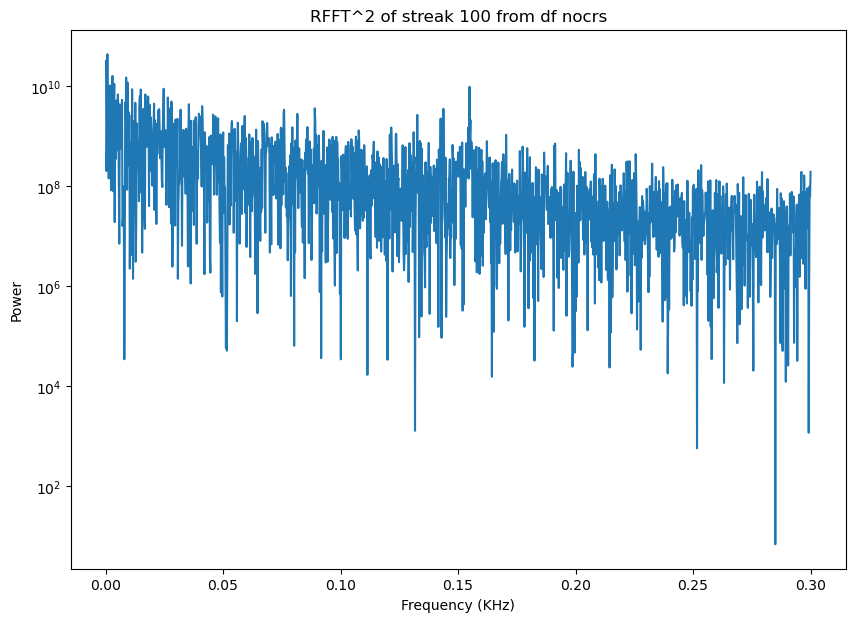

In [94]:
output_no, freqs_ms = get_rfft_sq(
    100, "1020", nocrs, half_aperture=2, tracking=True, plot=True
)

(0.1545, 0.155)

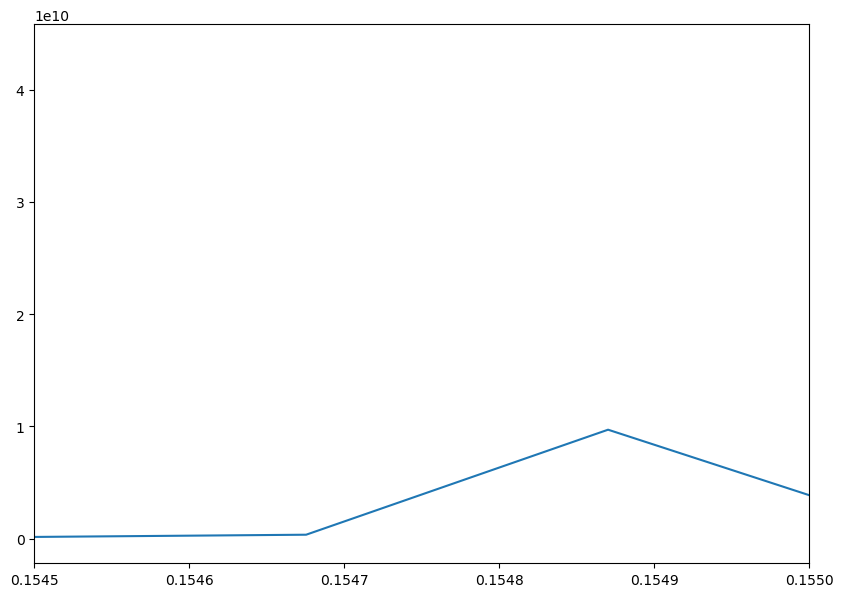

In [113]:
plt.plot(freqs_ms[1:], output_no)
plt.xlim(0.1545, 0.155)

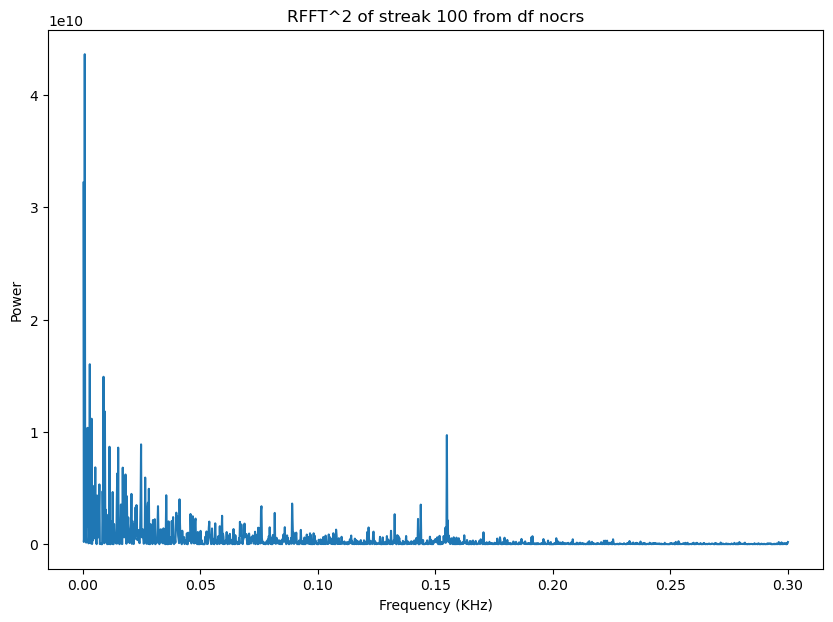

In [107]:
output_no, freqs_ms = get_rfft_sq(
    100, "1020", nocrs, half_aperture=2, tracking=True, plot=True
)

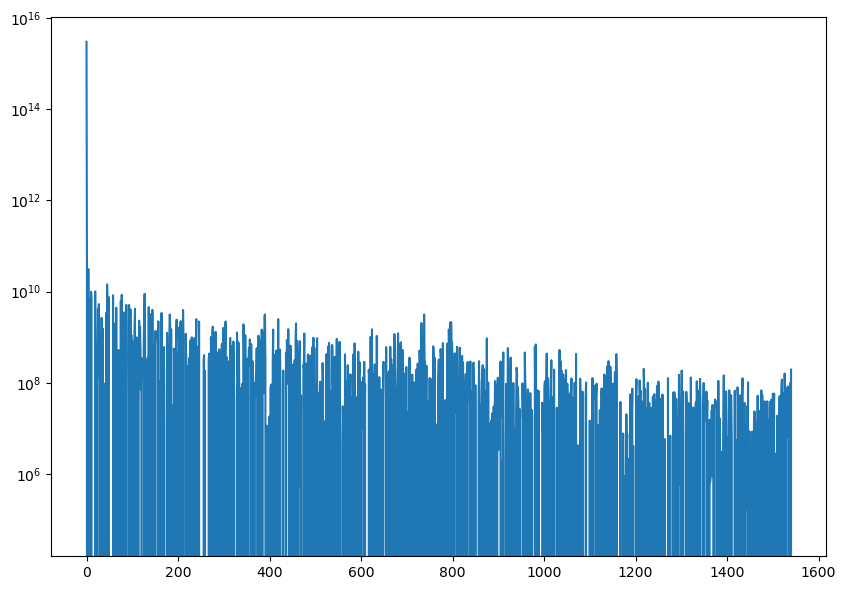

In [157]:
from scipy.fft import rfft, irfft, rfftfreq

# Compute FFT and get frequencies
tot, maxcols = get_tot(nocrs, 100, "1020", half_aperture=2, tracking=True)


# Step 1: Compute FFT and get frequencies
Fs = 1  # Assuming pixel as unit for FFT frequency calculation
N = len(tot)
fft_vals = rfft(tot)
freqs = rfftfreq(N, d=1 / Fs)

# Step 2: Convert frequencies to cycles per millisecond (mHz)
pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms

# Step 3: Define Gaussian band-stop filter parameters in mHz
target_freq_ms = (
    0.1549  # Target frequency in cycles per ms (replace with your specific value)
)
sigma_ms = 0.0001  # Width of Gaussian in cycles per ms

# Gaussian band-stop filter in cycles per ms
gaussian_filter = 1 - np.exp(-0.5 * ((freqs_ms - target_freq_ms) / sigma_ms) ** 2)

# Step 4: Apply the filter to FFT values
filtered_fft_vals = fft_vals * gaussian_filter

# Step 5: Inverse FFT to get the filtered signal back in time domain
filtered_tot = irfft(filtered_fft_vals)

# Plot the original and filtered signals for comparison
# plt.plot(tot, label='Original Signal')
# plt.plot(filtered_tot, label='Filtered Signal', linestyle='--')
# plt.legend()
# plt.xlabel("Pixel Index")
# plt.ylabel("Flux")
# plt.title("Original vs. Gaussian-Filtered Signal")
# plt.show()

# plt.plot(filtered_fft_vals)
plt.plot(np.square(fft_vals))
plt.yscale("log")

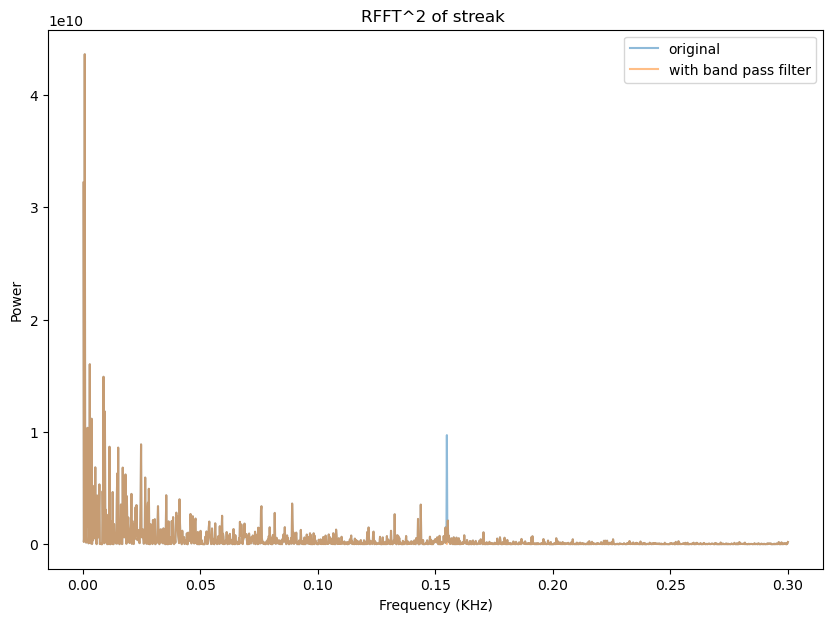

In [159]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1  # change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1 / Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=0.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label="with band pass filter", alpha=0.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)")  # cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

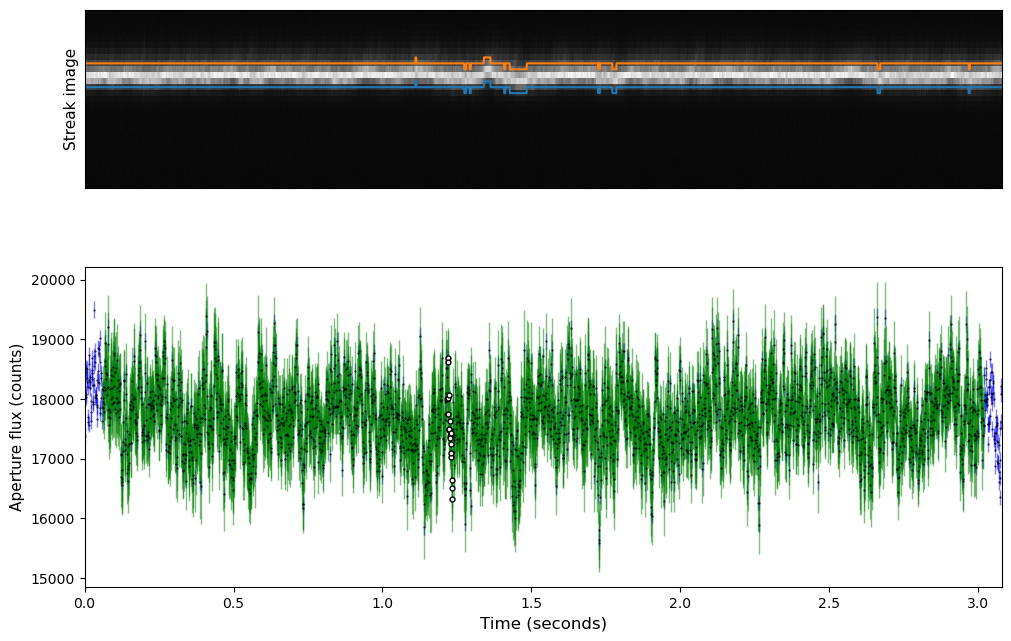

In [131]:
plot_tracking_options(
    df=nocrs, index=100, direcname="1020", half_aperture=2, tracking=True
)

Text(0, 0.5, 'Flux')

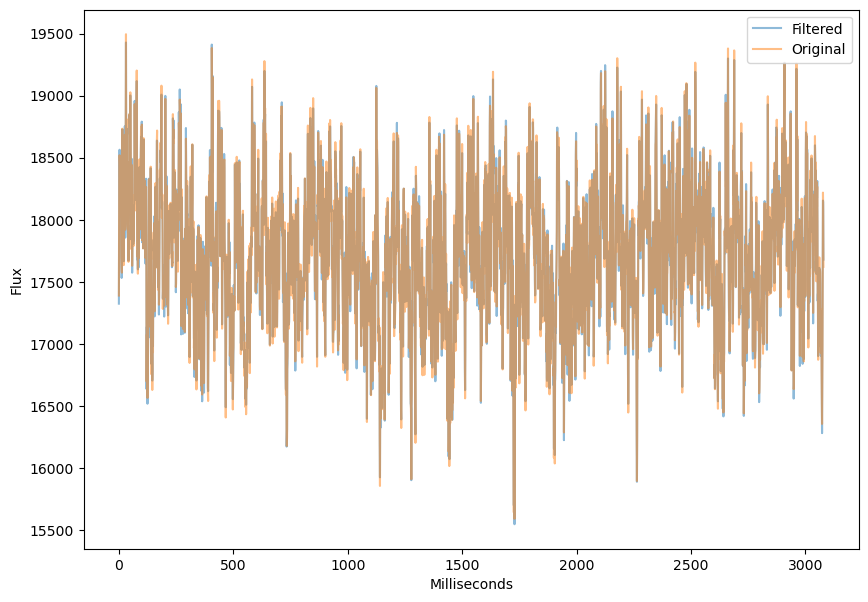

In [141]:
plt.plot(filtered_tot, alpha=0.5, label="Filtered")
plt.plot(tot, alpha=0.5, label="Original")
plt.legend()
plt.xlabel("Milliseconds")
plt.ylabel("Flux")

(1000.0, 1200.0)

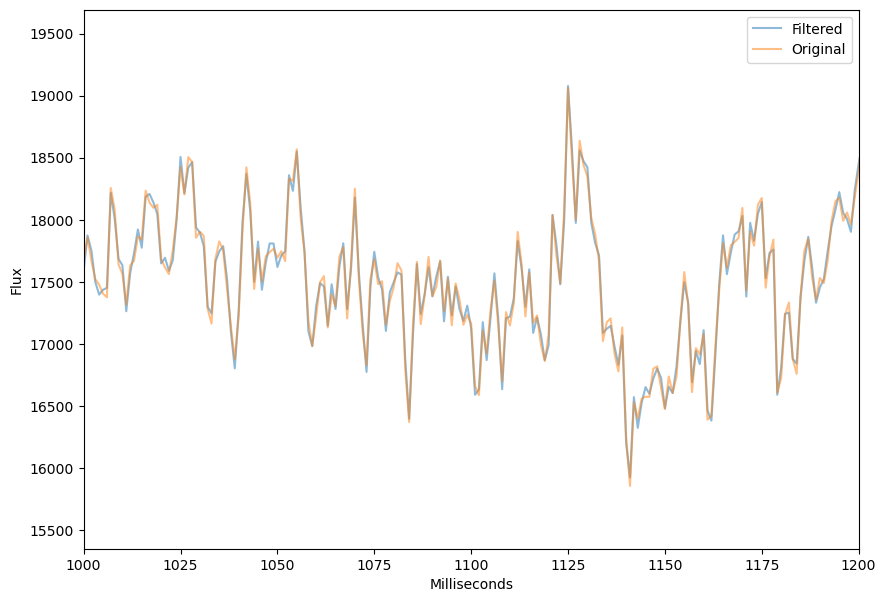

In [145]:
plt.plot(filtered_tot, alpha=0.5, label="Filtered")
plt.plot(tot, alpha=0.5, label="Original")
plt.legend()
plt.xlabel("Milliseconds")
plt.ylabel("Flux")
plt.xlim(1000, 1200)

Text(0.5, 0, 'Frequency')

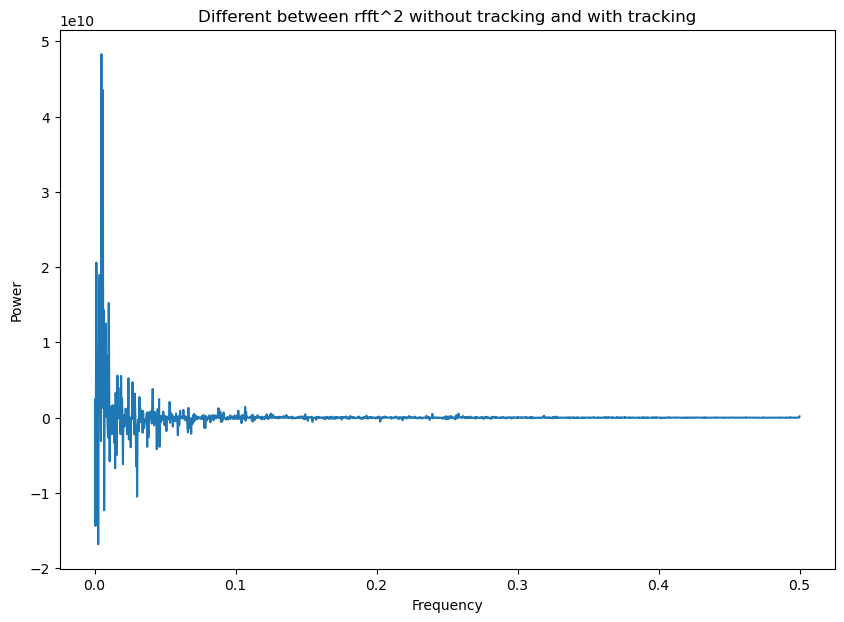

In [125]:
plt.plot(freqs[1:], output_no - output_w)
plt.title("Different between rfft^2 without tracking and with tracking")
plt.ylabel("Power")
plt.xlabel("Frequency")

(0.0, 100.0)

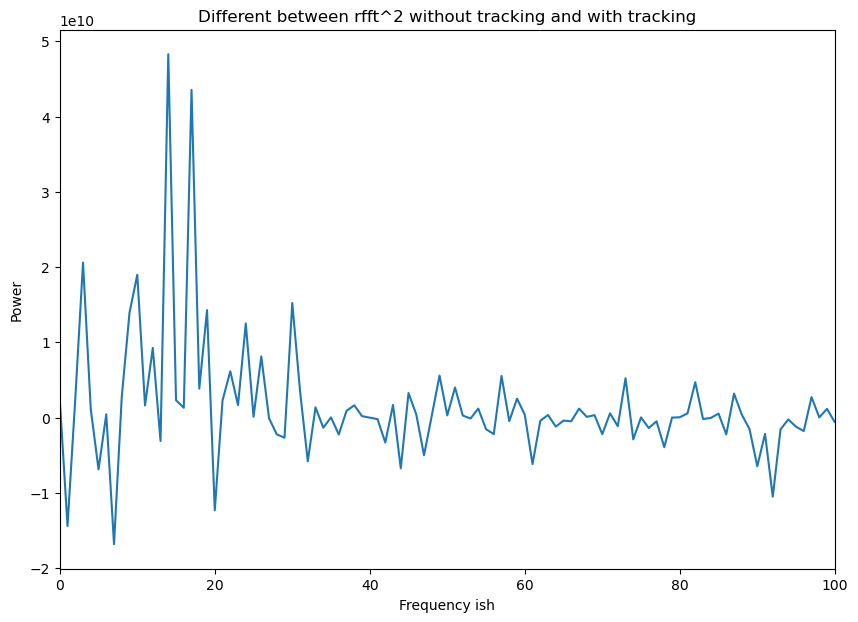

In [130]:
plt.plot(output_no - output_w)
plt.title("Different between rfft^2 without tracking and with tracking")
plt.ylabel("Power")
plt.xlabel("Frequency ish")
plt.xlim(0, 100)

In [16]:
def plot_time_series_zoom_occult(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)
    averages = np.average(
        imagenobackground[row - 10 : row + 10, col - 7 : col + 7], axis=0
    )
    zeropoint = col - 7

    maxind = np.argmax(averages)
    column_indices = [
        zeropoint + maxind - 4,
        zeropoint + maxind - 3,
        zeropoint + maxind - 2,
        zeropoint + maxind - 1,
        zeropoint + maxind,
        zeropoint + maxind + 1,
        zeropoint + maxind + 3,
        zeropoint + maxind + 4,
    ]

    streaks = np.zeros((len(column_indices), len(image[:, column])))
    for i, inde in enumerate(column_indices):
        streaks[i] = imagenobackground[:, inde]
        # streaks[i] = image[:,inde]
    streakavg = np.average(streaks, axis=0)
    tot = np.sum(streaks, axis=0)

    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 250, row + 200)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 250, row + 200)
    axd["lower mid"].set_xticks(np.linspace(row - 250, row + 200, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Occultation no tracking", fontsize=24)

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    plt.show()
    plt.close()

In [17]:
def plot_time_series_zoom_occult_tracking(df, index, direcname):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    wideval = 5
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[1].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array
    plt.rcParams["figure.figsize"] = (10, 7)
    plt.rcParams["image.interpolation"] = "nearest"
    plt.rcParams["image.cmap"] = "gist_gray"
    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(width_ratios=[2, 2], height_ratios=[1, 2])
    fig, axd = plt.subplot_mosaic(
        [["upper left", "upper mid"], ["lower left", "lower mid"]],
        gridspec_kw=gs_kw,
        figsize=(7.5, 3.5),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 20
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 40]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, wideval):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = round(combined)

    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt
    streakavg = tot

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    # axd['lower left'].set_ylim(0, 1499)
    # axd['lower mid'].set_ylim(0, 1499)

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 20, column + 20)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Summed streak flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["upper mid"].imshow(np.sqrt(image).T, aspect=3, cmap="gist_gray")
    axd["upper mid"].set_xlim(row - 250, row + 200)
    axd["upper mid"].set_ylim(column - 20, column + 20)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower mid'].set_xlim(row-30,row+30)
    axd["lower mid"].set_xlim(row - 250, row + 200)
    axd["lower mid"].set_xticks(np.linspace(row - 250, row + 200, 3))
    axd["upper mid"].set_axis_off()
    axd["lower mid"].set_yticks([])
    # axd['lower mid'].set_xticks(np.linspace(row-30,row+30, 3))
    axd["lower mid"].set_xlabel("Time (ms)", fontsize=12)
    axd["lower mid"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
    )
    # axd['lower left'].legend([" ","Poisson err.", "Stdv err."])
    axd["lower left"].legend()

    fig.suptitle("Occultation with tracking", fontsize=24)

    axd["lower mid"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 90 : row + 10],
        tot[row - 90 : row + 10],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=20,
    )

    plt.show()
    plt.close()

In [6]:
df_1019 = rff.getdf("1019")

/lustre/lrspec/ZTF_data/science_extractions/1019/df_detections_1019


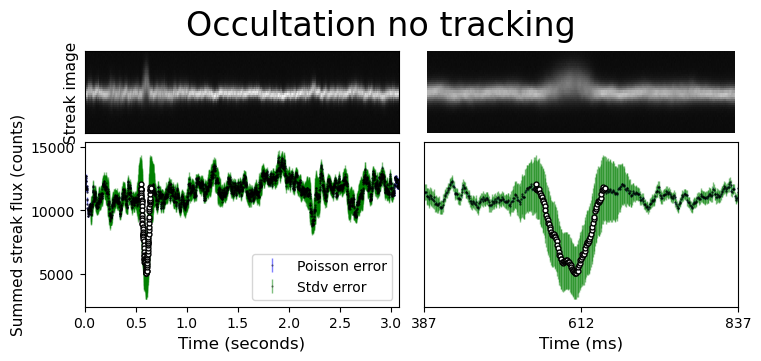

In [18]:
plot_time_series_zoom_occult(df_1019, 133424, "1019")

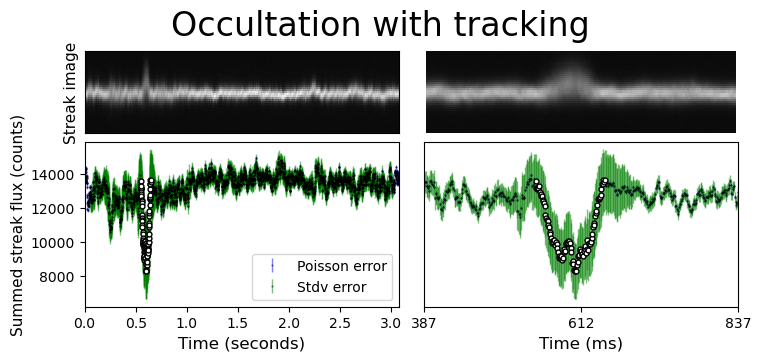

In [19]:
plot_time_series_zoom_occult_tracking(df_1019, 133424, "1019")

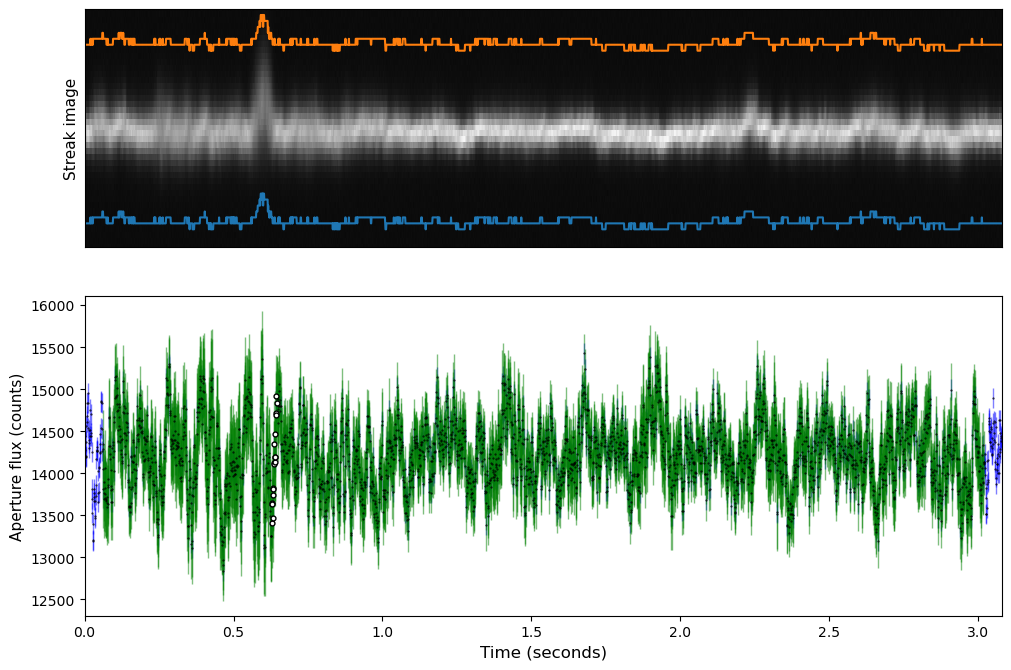

In [31]:
plot_tracking_wide(df_1019, 133424, "1019", quad=True, wideval=15)

In [7]:
plot_tracking_wide(nocrs, 100, "1020", wideval=15)

NameError: name 'plot_tracking_wide' is not defined

In [ ]:
"""
We shall quantify the change in standard deviation with tracking vs no tracking



"""

In [45]:
def get_stdvs(tot, do_all=True, df=None, index=None):
    if do_all == True:
        stdvs = np.zeros(len(tot))
        for i in range(len(tot)):
            if i > 60 and i < (len(tot) - 60):
                arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
                stdvs[i] = np.std(arr)
    else:
        row = int(df.iloc[index]["row_from_nn"]) + 10
        arr = np.concatenate((tot[row - 60 : row - 10], tot[row + 10 : row + 60]))
        stdvs = np.std(arr)
    return stdvs

In [19]:
def get_tot(df, index, direcname, half_aperture, tracking=True):
    """ """
    wideval = half_aperture
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = (
        int(df.iloc[index]["row_from_nn"]) + 10
    )  # we add 10 here bc that's the cnn offset of returned values
    col = int(df.iloc[index]["col_from_nn"]) + 10
    quad = int(df.iloc[index]["quadrant"])
    column = int(col)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    image = file1_array

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    if tracking == False:
        zeropoint = col - 7
        averages = np.average(
            imagenobackground[row - 10 : row + 10, zeropoint : zeropoint + 14], axis=0
        )
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(
            0, imagenobackground.shape[0]
        ):  # this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1, half_aperture + 1):
                combined += imagenobackground[r, maxcol - i]
                combined += imagenobackground[r, maxcol + i]
            tot2[r] = combined
        return tot2, np.full(len(tot2), maxcol)

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 10
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 20]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, half_aperture + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined

    return tot, maxcols

In [23]:
def plot_tracking_options(df, index, direcname, half_aperture, tracking):
    """
    zoom in
    this plots a time series from a dataframe, making it and easy to diagnose
    inputs: dataframe, index, directory where the images live
    outputs: none, but plots.
    specifications: both poisson and stdv error, no normalization
    background is subtracted
    plots all the other transients also
    returns a dataframe missing the rows that were plotted
    """
    # wideval = 5
    # index=2
    # df=df_0820_short
    # direcname = "0820"
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = int(df.iloc[index]["row_from_nn"]) + 10
    col = int(df.iloc[index]["col_from_nn"]) + 10
    # if quad==True:
    #     quad=1
    # else:
    #     quad = int(df.loc[index]["quadrant"])
    quad = int(df.loc[index]["quadrant"])

    # print(testindex)
    # print(df.iloc[testindex]["filename"])

    # print("indices to check")
    # print(same_img_indices)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    norm = (file1_array - np.min(file1_array)) / (
        np.max(file1_array) - np.min(file1_array)
    )  # norm
    image = file1_array

    # plt.imshow(norm)
    # plt.xlim(1070,1170)
    # plt.ylim(100,120)

    column = int(col)

    # note: the scatter plots are shifted in the positive x direction by wid,
    # so that they line up with the images

    gs_kw = dict(height_ratios=[2, 2])

    fig, axd = plt.subplot_mosaic(
        [["upper left"], ["lower left"]],
        gridspec_kw=gs_kw,
        figsize=(10, 7),
        layout="constrained",
    )

    background = rff.get_image_background(image)

    imagenobackground = image - np.full(np.shape(image), background)

    # so we need to track the whole streak
    # for each row, need to choose a column index

    tot, maxcols = get_tot(df, index, direcname, half_aperture, tracking)

    sqrt = np.sqrt(tot)
    # fluxerr = np.divide(sqrt, len(column_indices))
    fluxerr = sqrt
    streakavg = tot  # i don't use this any more

    stderr = np.zeros(len(tot))
    for i in range(len(stderr)):
        if i > 60 and i < (len(stderr) - 60):
            arr = np.concatenate((tot[i - 60 : i - 10], tot[i + 10 : i + 60]))
            stderr[i] = np.std(arr)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols)
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols-1)
    axd["upper left"].plot(
        range(0, imagenobackground.shape[0]), maxcols - half_aperture
    )
    # axd['upper left'].plot(range(0, imagenobackground.shape[0]), maxcols+1)
    axd["upper left"].plot(
        range(0, imagenobackground.shape[0]), maxcols + half_aperture
    )

    axd["upper left"].imshow(np.sqrt(image).T, aspect=20, cmap="gist_gray")
    axd["upper left"].set_ylim(column - 15, column + 15)

    axd["upper left"].set_xticklabels([])
    axd["upper left"].set_yticklabels([])
    axd["upper left"].set_yticks([])
    axd["upper left"].set_xticks([])

    axd["lower left"].set_xticks(np.arange(0, len(image[:, column]), 500))
    axd["lower left"].set_xticklabels(
        np.arange(0, len(image[:, column]) / 1000, 500 / 1000)
    )

    axd["lower left"].set_xlim(0, len(image[:, column]))
    axd["lower left"].set_xlabel("Time (seconds)", fontsize=12)
    axd["lower left"].set_ylabel("Aperture flux (counts)", fontsize=11)
    axd["upper left"].set_ylabel("Streak image", fontsize=11)

    axd["lower left"].plot(
        np.arange(len(streakavg))[row - 9 : row + 9],
        tot[row - 9 : row + 9],
        color="white",
        linestyle="none",
        marker=".",
        markersize=7,
        markeredgecolor="black",
        zorder=10,
    )

    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=fluxerr,
        color="black",
        ecolor="blue",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Poisson error",
    )
    # s=np.full(len(image[:,column])-2*wid,3), norm=mpl.colors.Normalize(vmin=0, vmax=6),
    # marker="|", c=cimg.T[:,column-10], cmap="prism")
    axd["lower left"].errorbar(
        np.arange(len(streakavg)),
        tot,
        yerr=stderr,
        color="black",
        ecolor="green",
        elinewidth=1,
        linestyle="none",
        marker=".",
        markersize=1,
        alpha=0.5,
        label="Stdv error",
    )

    plt.show()
    plt.close()

In [36]:
tot, maxcols = get_tot(
    df=nocrs, index=100, direcname="1020", half_aperture=2, tracking=True
)

In [56]:
np.average(tot)
stdv = get_stdvs(tot, do_all=True, df=nocrs, index=100)
# plt.plot(stdv[61:-60])
print(np.average(tot), np.average(stdv[61:-60]))

17711.937728604404 525.3341813186044


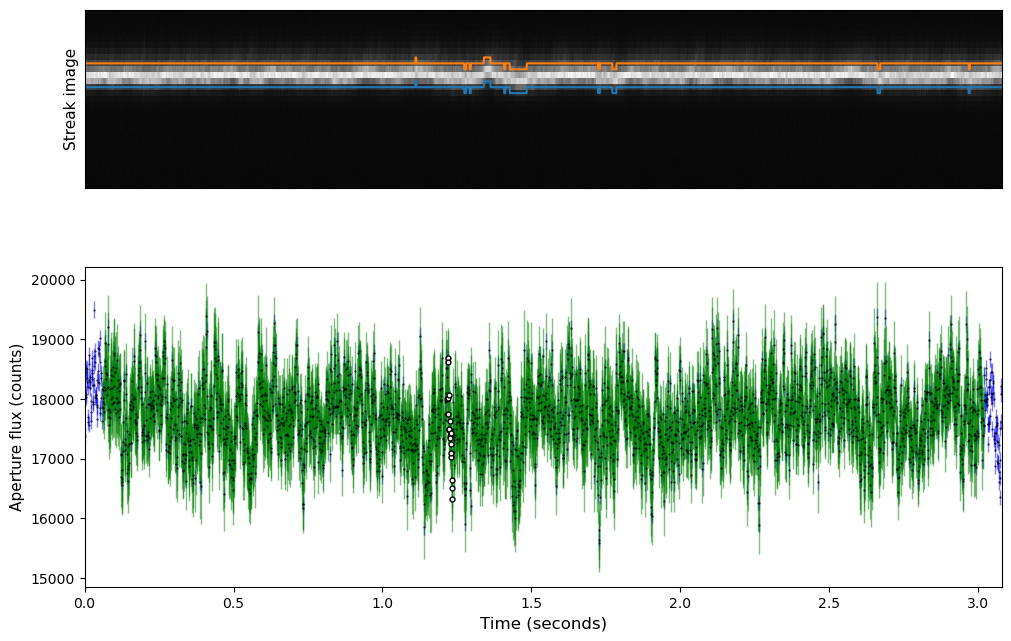

In [35]:
plot_tracking_options(
    df=nocrs, index=100, direcname="1020", half_aperture=2, tracking=True
)

In [125]:
tot

array([4341.065979  , 4445.94439697, 4370.66186523, ..., 4546.61405945,
       4371.90211487, 4621.49891663])

In [129]:
tot2 = get_tot(nocrs, 10, "1020", half_aperture=2, tracking=False)

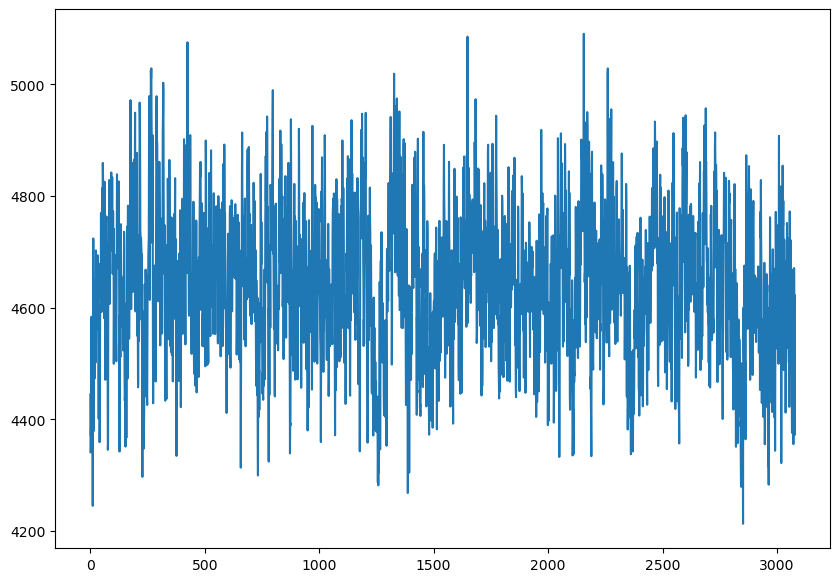

In [130]:
# plt.plot(tot1)
plt.plot(tot2)

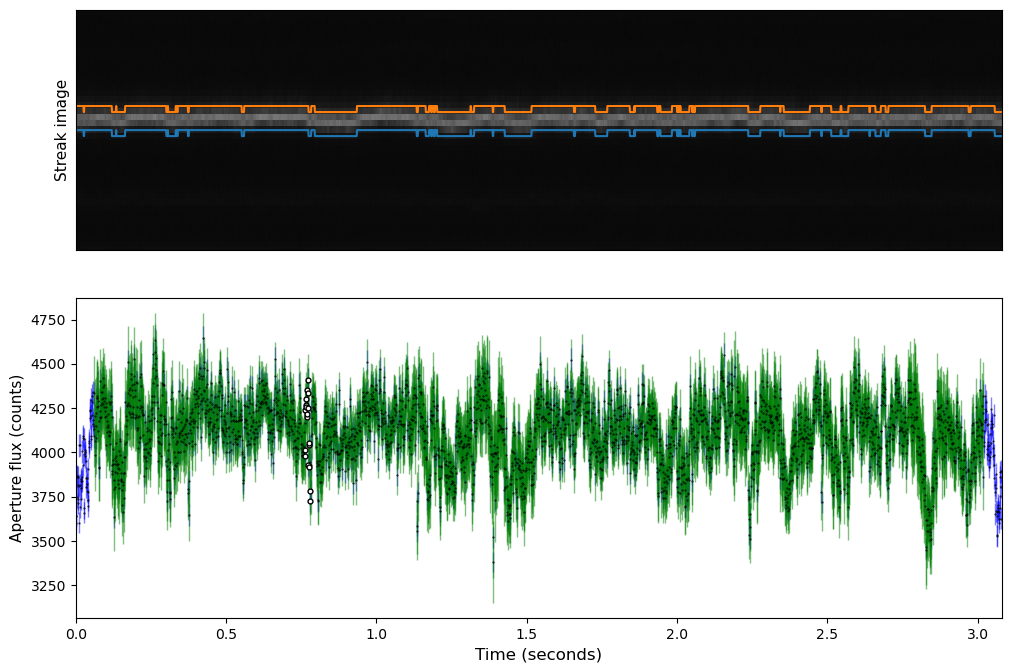

In [15]:
plot_tracking_wide(nocrs, 10, "1020", wideval=2)

<ErrorbarContainer object of 3 artists>

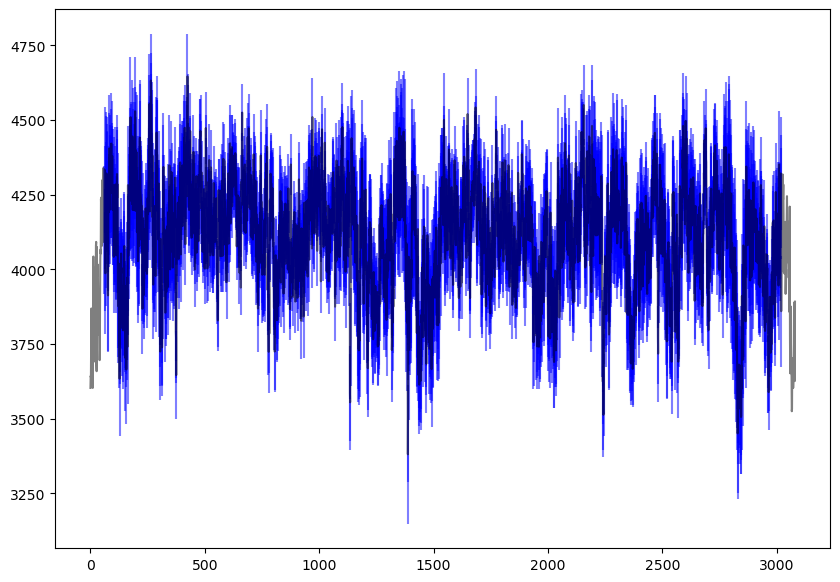

In [39]:
tot = get_tot(nocrs, 10, "1020", half_aperture=2)
stdvs, stderr = get_stdvs(tot)
plt.errorbar(
    np.linspace(0, len(tot), len(tot + 1)),
    tot,
    yerr=stderr,
    color="black",
    ecolor="blue",
    alpha=0.5,
)

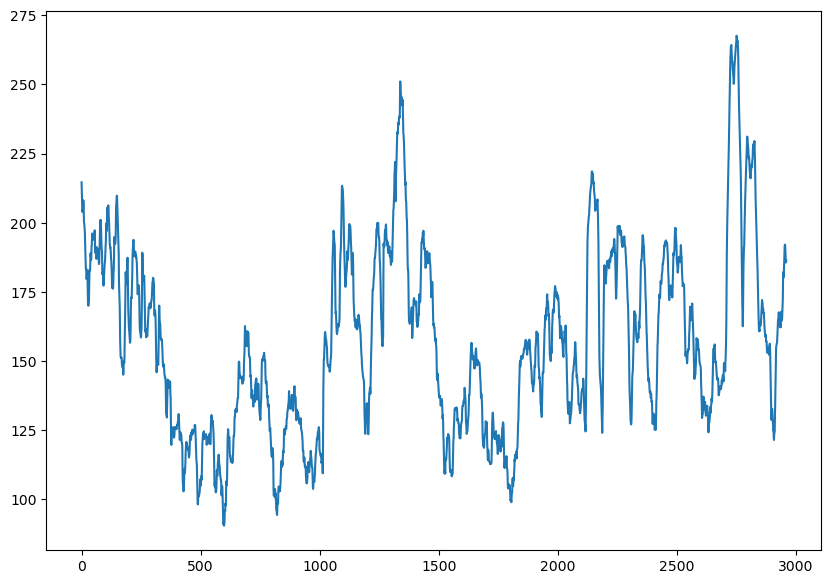

In [40]:
plt.plot(stdvs)

In [41]:
len(nocrs)

610903

In [ ]:
tot = get_tot(nocrs, 10, "1020", half_aperture=2)
stdvs, stderr = get_stdvs(tot)
plt.errorbar(
    np.linspace(0, len(tot), len(tot + 1)),
    tot,
    yerr=stderr,
    color="black",
    ecolor="blue",
    alpha=0.5,
)

In [61]:
tot = get_tot(nocrs, 10, "1020", half_aperture=2)
stds_one = get_stdvs(tot, do_all=False, df=nocrs, index=10)

In [62]:
stds_one

144.8363849314115

In [57]:
np.random.seed(42)
x = [np.random.randint(0, len(nocrs) + 1) for p in range(0, 100)]

In [151]:
avstds_2_tracking = np.zeros(len(x))
avgbrightness_2_tracking = np.zeros(len(x))
avg_2_tracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, "1020", half_aperture=2, tracking=True)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstd = np.average(stdvs)
    avgbrightness_2_tracking[i] = np.average(tot)
    avstds_2_tracking[i] = avstd
    avg_2_tracking[i] = avstd / np.average(tot)

In [78]:
print(np.average(avstds_2), np.average(avgbrightness))
print(np.average(avstds_1_tracking), np.average(avgbrightness_1_tracking))
print(np.average(avstds_1_notracking), np.average(avgbrightness_1_notracking))
print(np.average(avstds_2_notracking), np.average(avgbrightness_2_notracking))

314.0068654447457 12413.093735399218
421.6098775928842 10473.762656683586
419.2493368463906 10153.474892521253
296.01817296506823 12316.165302535514


In [163]:
print("ap 2 no tracking, average of stdv/mean: ", np.average(avg_2_notracking))
print("stdv of that array: ", np.std(avg_2_notracking))
print("\n")
print("ap 1 no tracking, average of stdv/mean: ", np.average(avg_1_notracking))
print("stdv of that array: ", np.std(avg_1_notracking))
print("\n")
print("ap 2 with tracking, average of stdv/mean: ", np.average(avg_2_tracking))
print("stdv of that array: ", np.std(avg_2_tracking))
print("\n")
print("ap 1 with tracking, average of stdv/mean: ", np.average(avg_1_tracking))
print("stdv of that array: ", np.std(avg_1_tracking))

ap 2 no tracking, average of stdv/mean:  0.02496570553533173
stdv of that array:  0.005010229053188529


ap 1 no tracking, average of stdv/mean:  0.039628273794688675
stdv of that array:  0.01290549675962654


ap 2 with tracking, average of stdv/mean:  0.026151476859992816
stdv of that array:  0.008341975072050098


ap 1 with tracking, average of stdv/mean:  0.038729680398240984
stdv of that array:  0.013051221144692482


In [67]:
tot, maxcol = get_tot(nocrs, x[0], "1020", half_aperture=1, tracking=True)

In [69]:
stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=x[0])

In [71]:
np.average(stdvs)

436.5213114629762

In [147]:
avstds_1_tracking = np.zeros(len(x))
avgbrightness_1_tracking = np.zeros(len(x))
avg_1_tracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, "1020", half_aperture=1, tracking=True)
    avstd = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avgbrightness_1_tracking[i] = np.average(tot)
    avstds_1_tracking[i] = avstd
    avg_1_tracking[i] = avstd / np.average(tot)

In [ ]:
avstds_2_notracking = np.zeros(len(x))
avgbrightness_2_notracking = np.zeros(len(x))
avg_2_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, "1020", half_aperture=2, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstd = np.average(stdvs)
    avgbrightness_2_notracking[i] = np.average(tot)
    avstds_2_notracking[i] = avstd
    avg_2_notracking[i] = avstd / np.average(tot)

In [ ]:
avstds_1_notracking = np.zeros(len(x))
avgbrightness_1_notracking = np.zeros(len(x))
avg_1_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, "1020", half_aperture=1, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstd = np.average(stdvs)
    avgbrightness_1_notracking[i] = np.average(tot)
    avstds_1_notracking[i] = avstd
    avg_1_notracking[i] = avstd / np.average(tot)

In [141]:
print(np.average(avstds_short_2))
print(np.average(avstds_short_1))

308.17053803360284
396.86827376370604


In [145]:
print(np.average(avstds_short_2_notracking))
print(np.average(avstds_short_1_notracking))

304.22124716929267
417.68214126143806


In [142]:
avstds_short_2_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot = get_tot(nocrs, index, "1020", half_aperture=2, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstds_short_2_notracking[i] = stdvs

In [144]:
avstds_short_1_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot = get_tot(nocrs, index, "1020", half_aperture=1, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstds_short_1_notracking[i] = stdvs

In [131]:
tot = get_tot(nocrs, 10, "1020", half_aperture=2, tracking=False)

In [132]:
tot_tr = get_tot(nocrs, 10, "1020", half_aperture=2, tracking=True)

In [134]:
get_stdvs(tot, do_all=False, df=nocrs, index=index)

138.12097103524164

In [135]:
get_stdvs(tot_tr, do_all=False, df=nocrs, index=index)

142.37083632115048

In [136]:
half_aperture = 2
tot = get_tot(nocrs, 10, "1020", half_aperture=half_aperture, tracking=False)
tot_tr = get_tot(nocrs, 10, "1020", half_aperture=half_aperture, tracking=True)
stdv_notr = get_stdvs(tot, do_all=False, df=nocrs, index=index)
stdv_tr = get_stdvs(tot_tr, do_all=False, df=nocrs, index=index)
print("for aperture ", 2 * half_aperture + 1)
print("with tracking, stdv of ", stdv_tr)
print("without tracking, stdv of ", stdv_notr)

for aperture  5
with tracking, stdv of  142.37083632115048
without tracking, stdv of  138.12097103524164


In [137]:
half_aperture = 1
tot = get_tot(nocrs, 10, "1020", half_aperture=half_aperture, tracking=False)
tot_tr = get_tot(nocrs, 10, "1020", half_aperture=half_aperture, tracking=True)
stdv_notr = get_stdvs(tot, do_all=False, df=nocrs, index=index)
stdv_tr = get_stdvs(tot_tr, do_all=False, df=nocrs, index=index)
print("for aperture ", 2 * half_aperture + 1)
print("with tracking, stdv of ", stdv_tr)
print("without tracking, stdv of ", stdv_notr)

for aperture  3
with tracking, stdv of  167.4751852112393
without tracking, stdv of  160.46653922834994


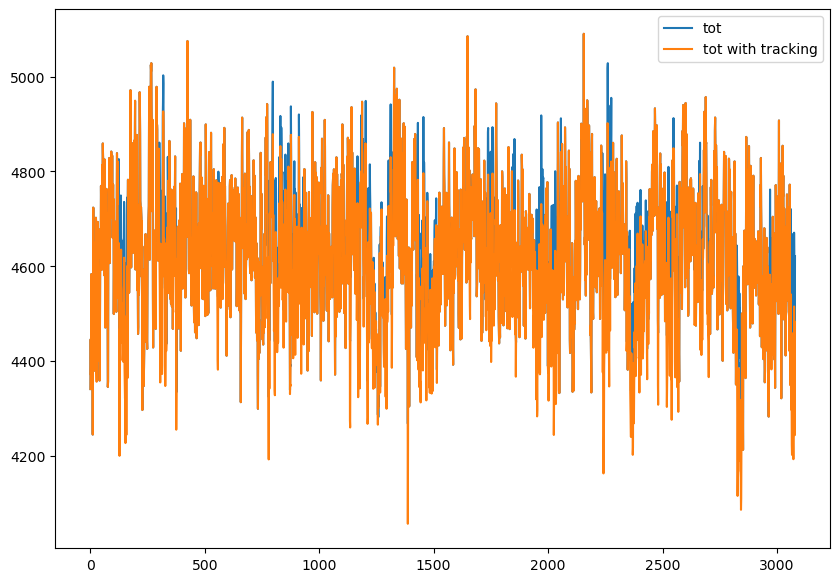

In [133]:
plt.plot(tot, label="tot")
plt.plot(tot_tr, label="tot with tracking")
plt.legend()

In [167]:
?get_tot

Signature: get_tot(df, index, direcname, half_aperture, tracking=True)
Docstring:     
File:      /tmp/ipykernel_32313/1241571390.py
Type:      function

In [168]:
tot, maxcols = get_tot(nocrs, 100, "1020", half_aperture=8, tracking=True)

In [170]:
tot2, maxcols = get_tot(nocrs, 100, "1020", half_aperture=3, tracking=True)

In [176]:
np.average(get_stdvs(tot))

469.0570444877958

In [177]:
np.average(get_stdvs(tot2))

479.25351151921257

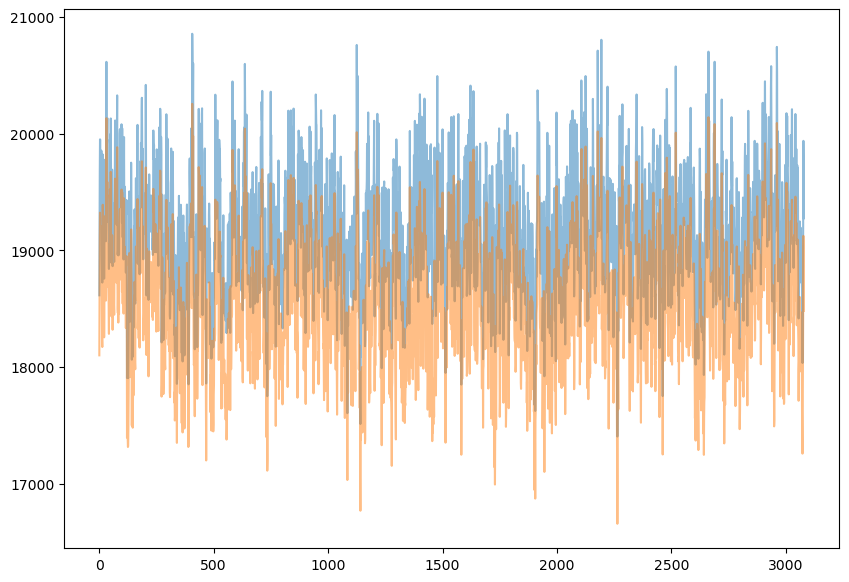

In [171]:
plt.plot(tot, alpha=0.5)
plt.plot(tot2, alpha=0.5)

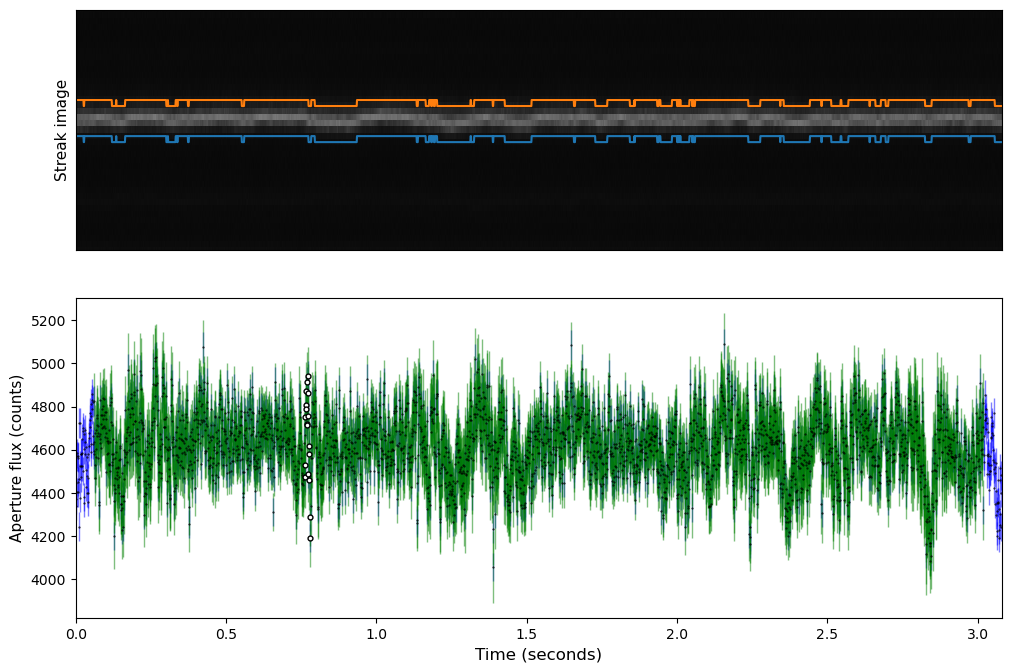

In [92]:
plot_tracking_wide(nocrs, 10, "1020", wideval=3)

In [143]:
get_stdvs(tot, do_all=False, df=nocrs, index=100)

508.9162103411305

In [142]:
get_stdvs(filtered_tot, do_all=False, df=nocrs, index=100)

504.02674689504215

In [191]:
peakindex = 0

(0.0, 500.0)

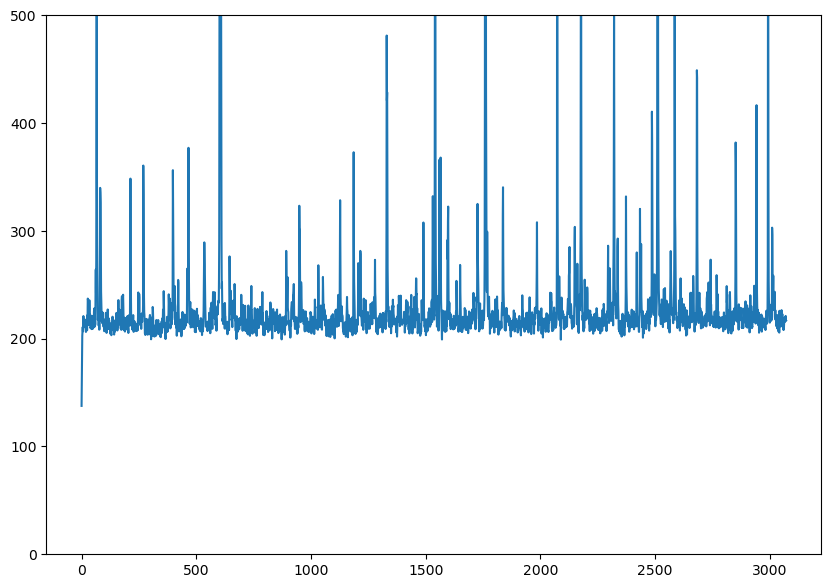

In [183]:
plt.plot(image[1000, :])
plt.ylim(0, 500)

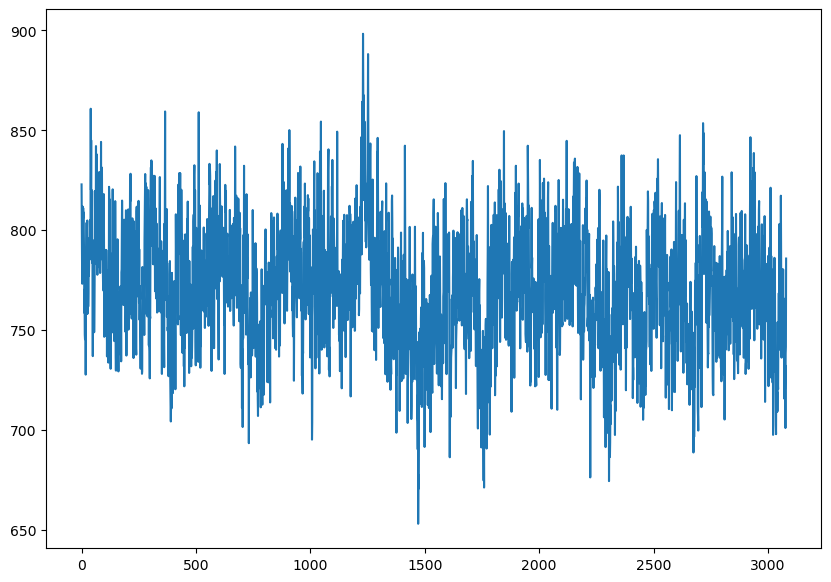

In [192]:
plt.plot(tot2)

In [181]:
from scipy.signal import find_peaks

In [184]:
peaks, _ = find_peaks(
    image[1000, :], height=500
)  # Adjust height threshold for your data

In [185]:
peaks

array([  66,  604, 1541, 1760, 2073, 2177, 2321, 2511, 2585, 2993])

In [198]:
all_streaks = []
for i in range(len(peaks)):
    tot = get_tot_streak(i)
    all_streaks.append(tot)

In [199]:
np.shape(all_streaks)

(10, 3080)

In [197]:
def get_tot_streak(peakindex):
    """ """
    df = nocrs
    index = 100
    direcname = "1020"
    half_aperture = 2
    tracking = False
    wideval = half_aperture
    wid = 10
    fname = df.iloc[index]["filename"] + "fits.fz"
    row = (
        int(df.iloc[index]["row_from_nn"]) + 10
    )  # we add 10 here bc that's the cnn offset of returned values
    # col = int(df.iloc[index]["col_from_nn"])+10
    col = peaks[peakindex]
    quad = int(df.iloc[index]["quadrant"])
    column = int(col)

    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
    path = fpath + fname
    hdul = fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    image = file1_array

    background = rff.get_image_background(image)
    imagenobackground = image - np.full(np.shape(image), background)
    if tracking == False:
        zeropoint = col - 7
        averages = np.average(
            imagenobackground[row - 10 : row + 10, zeropoint : zeropoint + 14], axis=0
        )
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(
            0, imagenobackground.shape[0]
        ):  # this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1, half_aperture + 1):
                combined += imagenobackground[r, maxcol - i]
                combined += imagenobackground[r, maxcol + i]
            tot2[r] = combined

    # so we need to track the whole streak
    # for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col - 10
    for r in range(0, imagenobackground.shape[0]):  # this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint : zeropoint + 20]) + zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1, half_aperture + 1):
            combined += imagenobackground[r, maxcol - i]
            combined += imagenobackground[r, maxcol + i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined

    return tot

In [ ]:
tot, maxcols = get_tot(nocrs, 100, "1020", half_aperture=2, tracking=True)

In [263]:
def get_filtered_fft(tot, target_freq_ms):
    # Compute FFT and get frequencies

    # Step 1: Compute FFT and get frequencies
    Fs = 1  # Assuming pixel as unit for FFT frequency calculation
    N = len(tot)
    fft_vals = rfft(tot)
    freqs = rfftfreq(N, d=1 / Fs)

    # Step 2: Convert frequencies to cycles per millisecond (mHz)
    pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
    freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms

    # Step 3: Define Gaussian band-stop filter parameters in mHz
    # target_freq_ms = .1549  # Target frequency in cycles per ms (replace with your specific value)
    sigma_ms = 0.0001  # Width of Gaussian in cycles per ms

    # Gaussian band-stop filter in cycles per ms
    gaussian_filter = 1 - np.exp(-0.5 * ((freqs_ms - target_freq_ms) / sigma_ms) ** 2)

    # Step 4: Apply the filter to FFT values
    filtered_fft_vals = fft_vals * gaussian_filter

    # Step 5: Inverse FFT to get the filtered signal back in time domain
    filtered_tot = irfft(filtered_fft_vals)

    return filtered_fft_vals, filtered_tot, freqs_ms

In [296]:
tot, maxcols = get_tot(nocrs, 100, "1020", half_aperture=2, tracking=True)

/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


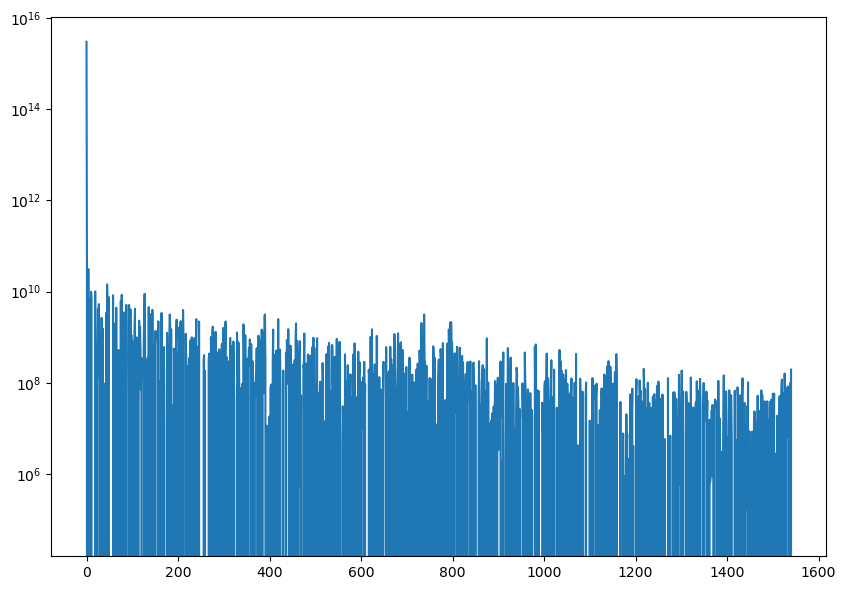

In [264]:
# Compute FFT and get frequencies
tot, maxcols = get_tot(nocrs, 100, "1020", half_aperture=2, tracking=True)


# Step 1: Compute FFT and get frequencies
Fs = 1  # Assuming pixel as unit for FFT frequency calculation
N = len(tot)
fft_vals = rfft(tot)
freqs = rfftfreq(N, d=1 / Fs)

# Step 2: Convert frequencies to cycles per millisecond (mHz)
pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms

# Step 3: Define Gaussian band-stop filter parameters in mHz
target_freq_ms = (
    0.1549  # Target frequency in cycles per ms (replace with your specific value)
)
sigma_ms = 0.0001  # Width of Gaussian in cycles per ms

# Gaussian band-stop filter in cycles per ms
gaussian_filter = 1 - np.exp(-0.5 * ((freqs_ms - target_freq_ms) / sigma_ms) ** 2)

# Step 4: Apply the filter to FFT values
filtered_fft_vals = fft_vals * gaussian_filter

# Step 5: Inverse FFT to get the filtered signal back in time domain
filtered_tot = irfft(filtered_fft_vals)

# Plot the original and filtered signals for comparison
# plt.plot(tot, label='Original Signal')
# plt.plot(filtered_tot, label='Filtered Signal', linestyle='--')
# plt.legend()
# plt.xlabel("Pixel Index")
# plt.ylabel("Flux")
# plt.title("Original vs. Gaussian-Filtered Signal")
# plt.show()

# plt.plot(filtered_fft_vals)
plt.plot(np.square(fft_vals))
plt.yscale("log")

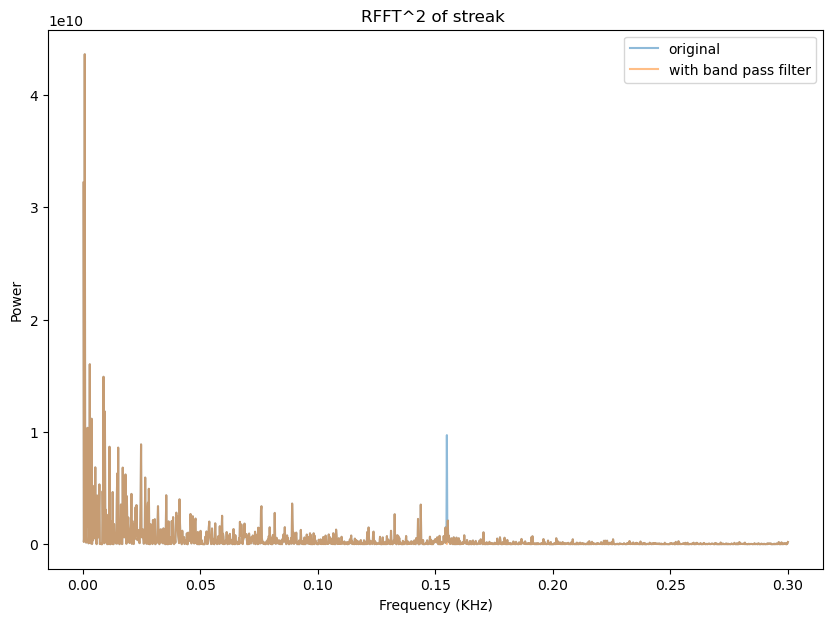

In [265]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))

filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(tot, target_freq_ms=0.1549)


sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1  # change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1 / Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=0.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label="with band pass filter", alpha=0.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)")  # cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

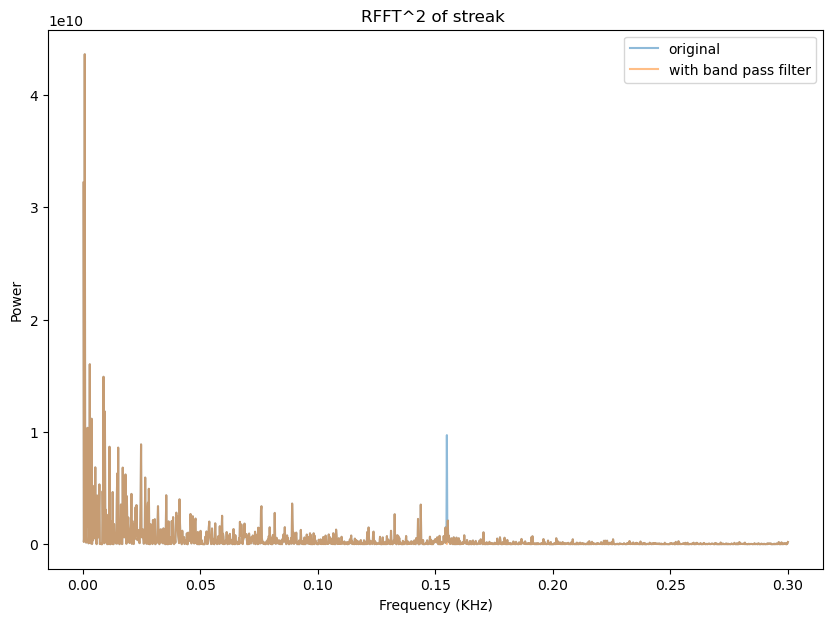

In [159]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1  # change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1 / Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=0.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label="with band pass filter", alpha=0.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)")  # cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

In [207]:
all_streaks[2]

array([1652.83117676, 1589.03283691, 1586.10839844, ..., 1671.83349609,
       1667.06005859, 1638.4185791 ])

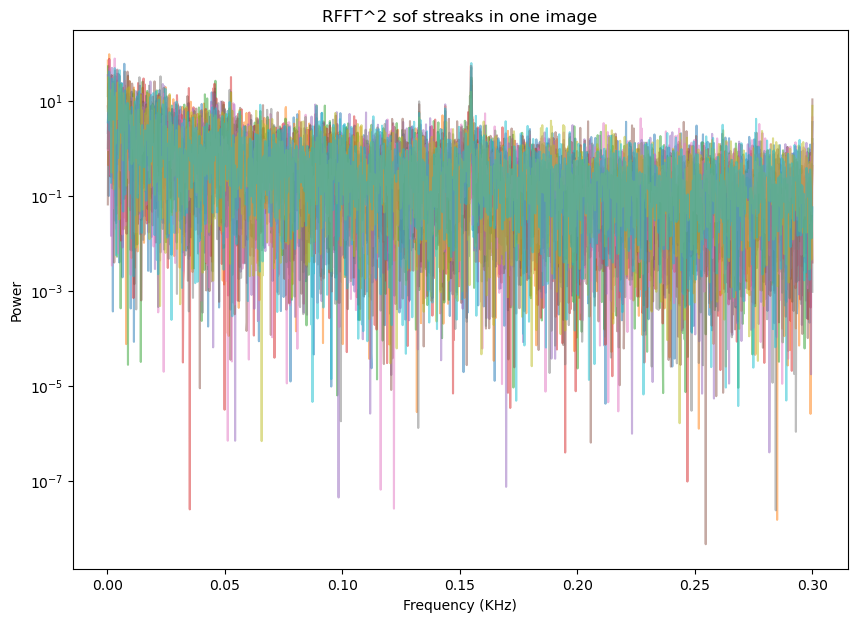

In [220]:
sqffts = []
freqsms = []
divideds = []
for streak in all_streaks:
    sqfft = np.square(np.real(np.fft.rfft(streak)[1:]))
    mean = np.average(sqfft)
    divided = sqfft / mean
    sqffts.append(sqfft)
    divideds.append(divided)
    Fs = 1  # change this if i want to change the sampling rate - right now, it's pixels
    N = len(tot)
    freqs = np.fft.rfftfreq(N, d=1 / Fs)

    pixel_to_ms_factor = 1 / 0.6
    freqs_ms = freqs / pixel_to_ms_factor
    freqsms.append(freqs_ms)

    plt.plot(freqs_ms[1:], divided, alpha=0.5)
    plt.ylabel("Power")
    plt.xlabel("Frequency (KHz)")  # cycles per millisecond
    plt.title("RFFT^2 sof streaks in one image")
    # plt.legend()
    plt.yscale("log")

In [225]:
len(divideds)

10

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


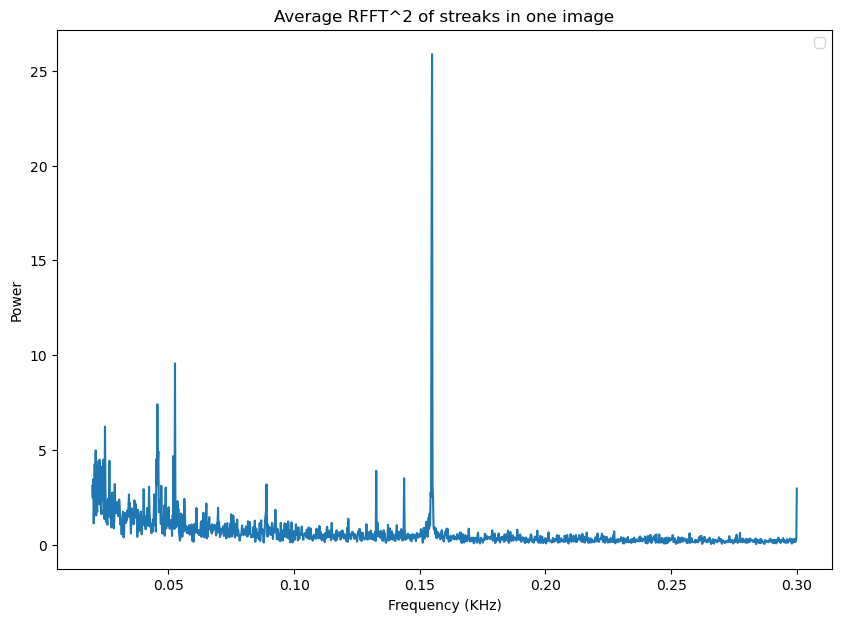

In [258]:
plt.plot(freqs_ms[1:][100:], np.average(divideds, axis=0)[100:])
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)")  # cycles per millisecond
plt.title("Average RFFT^2 of streaks in one image")
plt.legend()
# plt.yscale("log")
# plt.xscale("log")
# plt.xlim(0.01, .056)

In [254]:
avgs = np.average(divideds, axis=0)

In [259]:
peaks_ft, _ = find_peaks(avgs[100:], height=5)  # Adjust height threshold for your data

In [260]:
peaks_ft

array([ 26, 133, 169, 694])

In [266]:
filtered_tot = tot
for peak in peaks_ft:
    allfreqms = freqs_ms[101:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(
        filtered_tot, target_freq_ms=tofilter
    )

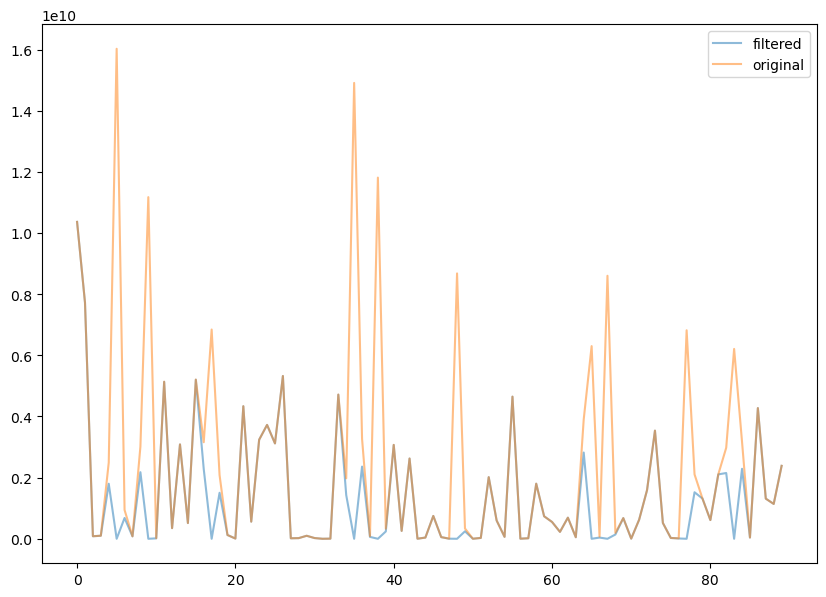

In [288]:
plt.plot(
    np.square(np.real(np.fft.rfft(filtered_tot)[10:100])), label="filtered", alpha=0.5
)
plt.plot(np.square(np.real(np.fft.rfft(tot)[10:100])), label="original", alpha=0.5)
plt.legend()

In [284]:
peaks_ft2, _ = find_peaks(
    np.square(np.real(np.fft.rfft(filtered_tot)[10:100])), height=0.6e10
)

In [287]:
peaks_ft2

array([ 5,  9, 17, 35, 38, 48, 65, 67, 77, 83])

In [298]:
filtered_tot = tot
for peak in peaks_ft2:
    allfreqms = freqs_ms[10:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(
        filtered_tot, target_freq_ms=tofilter
    )

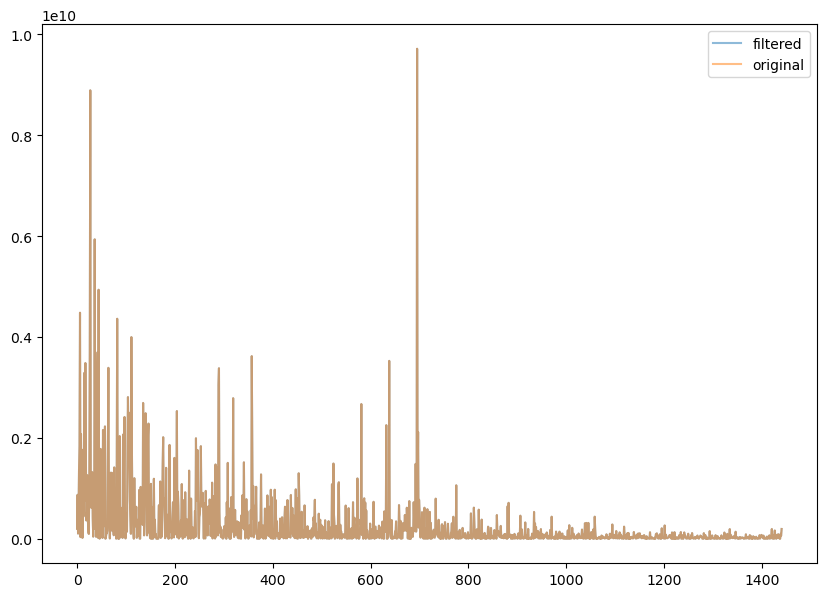

In [297]:
plt.plot(
    np.square(np.real(np.fft.rfft(filtered_tot)[100:])), label="filtered", alpha=0.5
)
plt.plot(np.square(np.real(np.fft.rfft(tot)[100:])), label="original", alpha=0.5)
plt.legend()

In [300]:
peaks_ft3, _ = find_peaks(
    np.square(np.real(np.fft.rfft(filtered_tot)[100:])), height=0.3e10
)

In [301]:
for peak in peaks_ft3:
    allfreqms = freqs_ms[100:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(
        filtered_tot, target_freq_ms=tofilter
    )

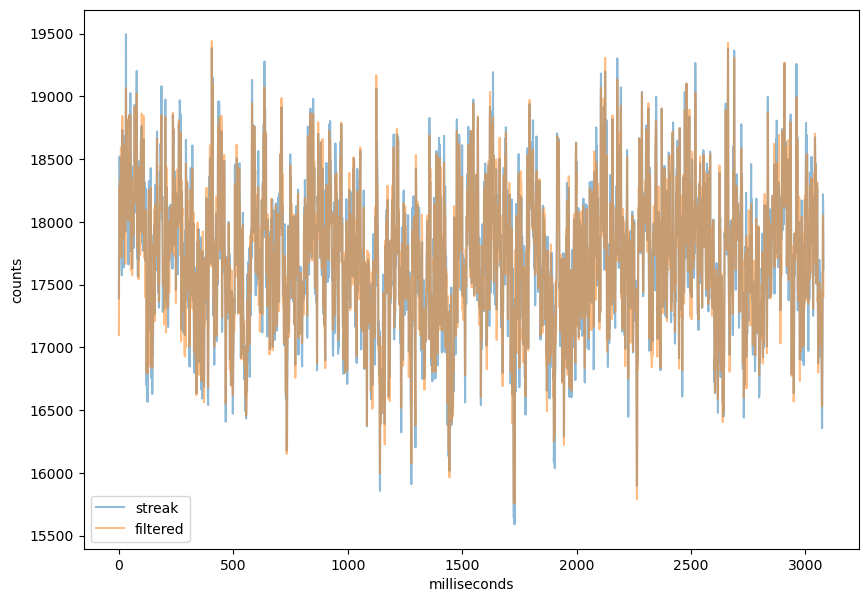

In [315]:
plt.plot(tot, label="streak", alpha=0.5)
plt.plot(filtered_tot, label="filtered", alpha=0.5)
# plt.xlim(100,200)
plt.xlabel("milliseconds")
plt.ylabel("counts")
plt.legend()

In [316]:
peaks_ft4, _ = find_peaks(
    np.square(np.real(np.fft.rfft(filtered_tot)[1:])), height=0.2e10
)

In [317]:
peaks_ft4

array([  3,   7,   9,  14,  18,  20,  22,  24,  26,  30,  33,  35,  42,
        44,  47,  49,  51,  57,  61,  64,  74,  76,  82,  86,  92,  95,
        98, 107, 125, 140, 152, 156, 186, 193, 196, 203, 205, 234, 239,
       245, 275, 303, 388, 418, 680, 731, 796])

In [318]:
for peak in peaks_ft4:
    allfreqms = freqs_ms[1:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(
        filtered_tot, target_freq_ms=tofilter
    )

In [319]:
np.average(get_stdvs(filtered_tot))

399.78746308990543

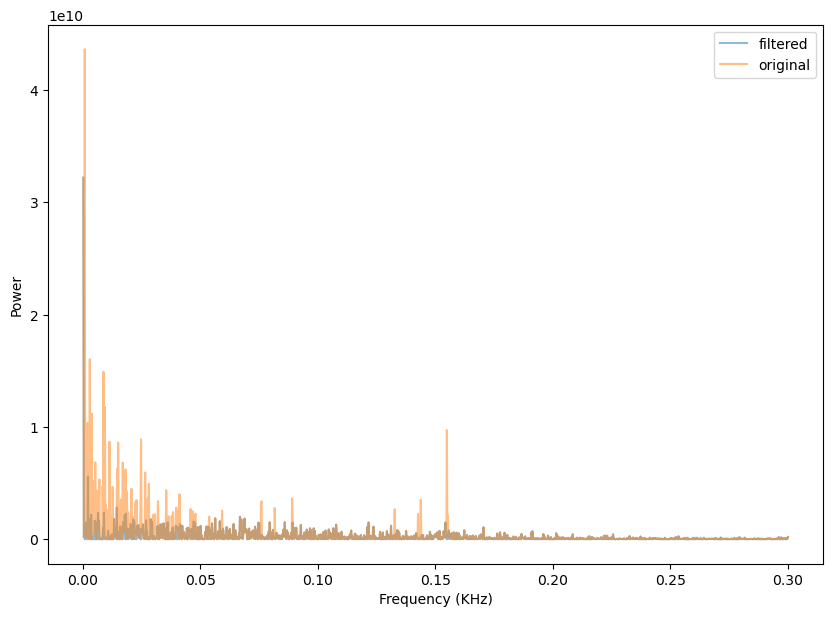

In [329]:
plt.plot(
    freqs_ms[1:],
    np.square(np.real(np.fft.rfft(filtered_tot)[1:])),
    label="filtered",
    alpha=0.5,
)
plt.plot(
    freqs_ms[1:], np.square(np.real(np.fft.rfft(tot)[1:])), label="original", alpha=0.5
)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)")  # cycles per millisecond
# plt.title("Average RFFT^2 of streaks in one image")
plt.legend()

Text(0.5, 1.0, 'Streak and streak after fourier filtering')

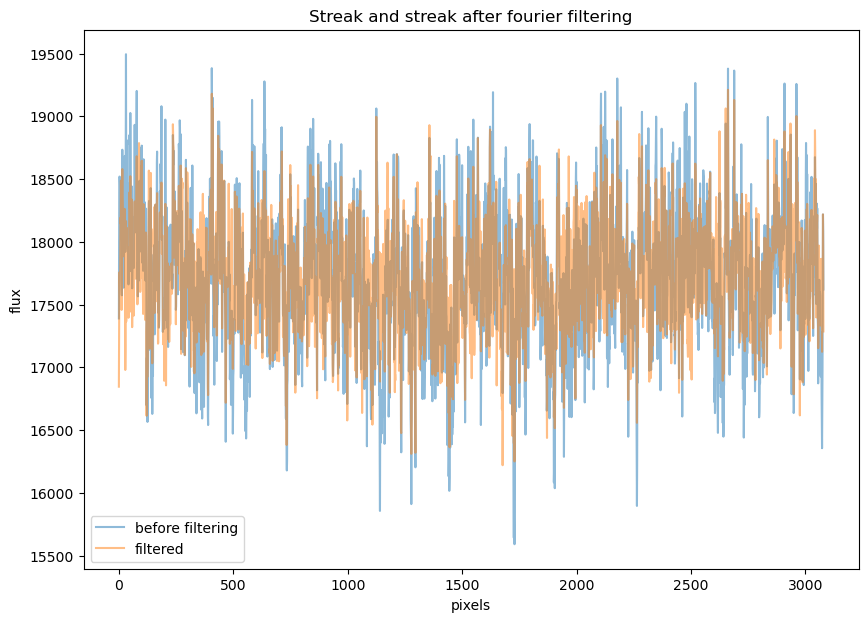

In [328]:
plt.plot(tot, label="before filtering", alpha=0.5)
plt.plot(filtered_tot, label="filtered", alpha=0.5)
# plt.ylabel("Power")
# plt.xlabel("Frequency (KHz)") #cycles per millisecond
# plt.title("Average RFFT^2 of streaks in one image")
plt.legend()
# plt.yscale("log")
# plt.xscale("log")
# plt.xlim(0.01, .056)
plt.xlabel("pixels")
plt.ylabel("flux")
plt.title("Streak and streak after fourier filtering")

In [ ]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))

filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(tot, target_freq_ms=0.1549)


sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1  # change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1 / Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=0.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label="with band pass filter", alpha=0.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)")  # cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

In [232]:
def get_milliseconds_from_khz(freq):
    # we have cycles/millisecond
    mspercycle = 1 / freq
    secpercycle = mspercycle / 1000
    pixpercycle = mspercycle * 6 / 10
    return mspercycle, secpercycle, pixpercycle

In [253]:
get_milliseconds_from_khz(0.3)

(3.3333333333333335, 0.0033333333333333335, 2.0)

In [330]:
get_milliseconds_from_khz(0.001)

(1000.0, 1.0, 600.0)

(100.0, 200.0)

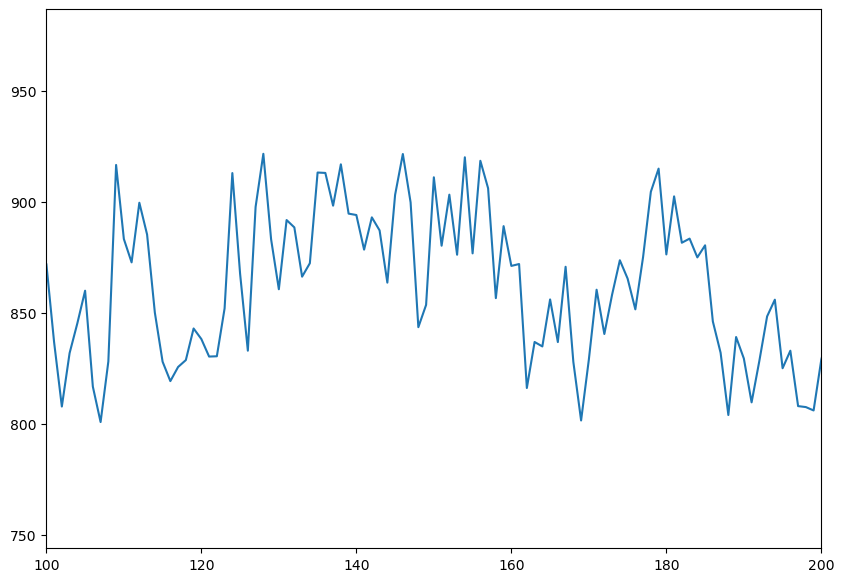

In [239]:
plt.plot(tot)
plt.xlim(100, 200)